## Model Comparison Using Algorithm B1
# Plot AULD algorithm<br>
Model Comparison Using Algorithm B1
To assess whether differences in cross-validation performance between competing GEV formulations are statistically significant, we apply the randomization test of Auld et al. (2023, Algorithm B1). For each pair of models, observation-level score differences are computed from the five-fold cross-validation results. Under the null hypothesis that the two models are equally skillful, the score differences are exchangeable and their signs may be randomly permuted. A null distribution of mean score differences is generated using 10^5 random sign permutations, and a one-sided p-value is estimated as the proportion of randomized statistics greater than or equal to the observed mean score difference. Small p-values indicate statistical support for the model with the lower average score.

In [1]:
import numpy as np
import xarray as xr
from pathlib import Path
from itertools import combinations
import cartopy
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
from matplotlib import cm
from matplotlib.transforms import blended_transform_factory

In [2]:
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.gridspec import GridSpec
import ensaio
import seaborn as sns

In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
state_borders =cartopy.feature.NaturalEarthFeature(category='cultural', name='admin_1_states_provinces_lakes', scale='50m', facecolor='none')
rivers = cartopy.feature.NaturalEarthFeature(category='physical',name='rivers_lake_centerlines',scale='50m',facecolor='none',edgecolor='blue')

In [5]:
latN = 50
latS = 25
lonW = -119.5
lonE = -74

cLat = (latN + latS)/2
cLon = (lonW + lonE )/2

In [6]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

In [27]:
# ============================================================
# INPUT FILES
# ============================================================
files = {"PrNO": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostLocSca_extremes_gev_1952_2025.nc",\
         "Pr14": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostpr14LocSca_extremes_gev_1952_2025.nc",
         "Pr30": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostpr30LocSca_extremes_gev_1952_2025.nc",
         #"Pr45": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostpr45LocSca_extremes_gev_1952_2025.nc",
         "Pr90": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostpr90LocSca_extremes_gev_1952_2025.nc",
         "Pr180": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostpr180LocSca_extremes_gev_1952_2025.nc"}

metrics = ["CRPS_cv","SE_cv","DawSeb_cv"]
models = list(files.keys())
models_name = {"PrNO": "$No Pr$","Pr14": r"$Pr_{14}$", "Pr30": r"$Pr_{30}$",  "Pr90": r"$Pr_{90}$", "Pr180": r"$Pr_{180}$"}
# ============================================================"Pr45": r"$Pr_{45}$",
# READ MODEL DATASETS
# ============================================================
datasets = {}
for model, file in files.items():
    print(f"Reading {model}")
    ds = xr.open_dataset(file)
    for metric in metrics:
        ds[metric] = (ds[metric].load())
    ds['AIC'] = ds['AIC'].load()    
    ds['BIC'] = ds['BIC'].load()    
    ds['rl'] = ds['rl'].load()
    if model=='PrNO':
        ds['covariate1'] = ds['covariate'].load()
    else:
        ds['covariate1'] = ds['covariate1'].load()
        ds['pvalue2'] = ds['pvalue2'].load()
        ds['pvalue3'] = ds['pvalue3'].load()
    datasets[model] = ds
    return_periods = ds.return_periods.data
    ds.close()
    
AEP = [1/irp for irp in return_periods]
units = '°F'    
# ============================================================
# BUILD PAIR LIST
# ============================================================
pairs = list(combinations(models, 2))
print(pairs)
# ============================================================
# READ ALGORITHM B1 RESULTS
# ============================================================
b1_files = {}
for model0, model1 in pairs:
    file_B1 = (f"/Users/gahe5417/data/TXx/"f"AlgorithmB1_glostpr{model0[2::]}LocSca_vs_glostpr{model1[2::]}LocSca.nc")
    print(f"Reading {Path(file_B1).name}")
    b1_files[(model0, model1)] = xr.open_dataset(file_B1)

landmask = datasets["PrNO"].AIC.notnull()

Reading PrNO
Reading Pr14
Reading Pr30
Reading Pr90
Reading Pr180
[('PrNO', 'Pr14'), ('PrNO', 'Pr30'), ('PrNO', 'Pr90'), ('PrNO', 'Pr180'), ('Pr14', 'Pr30'), ('Pr14', 'Pr90'), ('Pr14', 'Pr180'), ('Pr30', 'Pr90'), ('Pr30', 'Pr180'), ('Pr90', 'Pr180')]
Reading AlgorithmB1_glostprNOLocSca_vs_glostpr14LocSca.nc
Reading AlgorithmB1_glostprNOLocSca_vs_glostpr30LocSca.nc
Reading AlgorithmB1_glostprNOLocSca_vs_glostpr90LocSca.nc
Reading AlgorithmB1_glostprNOLocSca_vs_glostpr180LocSca.nc
Reading AlgorithmB1_glostpr14LocSca_vs_glostpr30LocSca.nc
Reading AlgorithmB1_glostpr14LocSca_vs_glostpr90LocSca.nc
Reading AlgorithmB1_glostpr14LocSca_vs_glostpr180LocSca.nc
Reading AlgorithmB1_glostpr30LocSca_vs_glostpr90LocSca.nc
Reading AlgorithmB1_glostpr30LocSca_vs_glostpr180LocSca.nc
Reading AlgorithmB1_glostpr90LocSca_vs_glostpr180LocSca.nc


Text(0.5, 0.98, 'Assessment of Antecedent Precipitation Covariates in TXx1 Models')

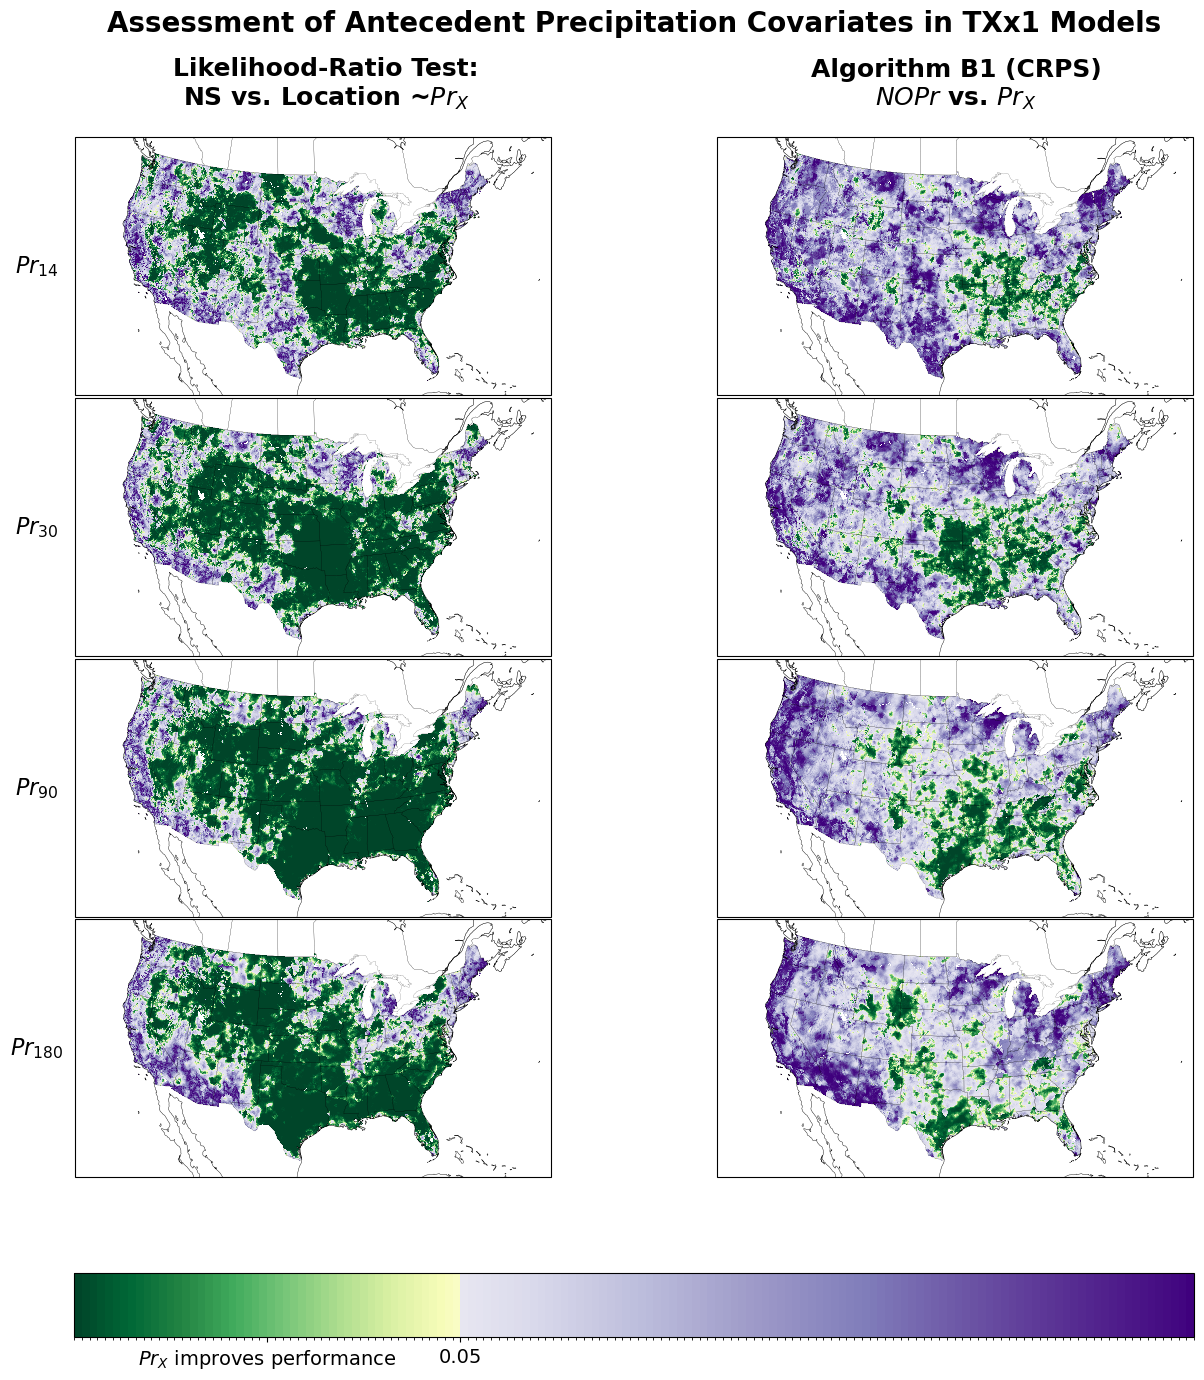

In [39]:
metric='CRPS_cv'   
alpha=0.05

metric_name = metric.replace("_cv", "")
# --------------------------------------------------
# Color convention
# -1 : row model significantly better
#  0 : no significant difference
# +1 : column model significantly better
# --------------------------------------------------
## Build colorbar
from matplotlib import cm
clevsa=np.arange(0.05,1.01,0.01)
clevsb=np.arange(0,0.05,0.001)
clevs_pv=np.concatenate((clevsb,clevsa))
cmap = cm.get_cmap('Purples',len(clevsa)+20)
cmaplist = [cmap(i) for i in range(20,cmap.N)]
cmap2 = cm.get_cmap('YlGn_r', len(clevsb)+5)
cmaplist2 = [cmap2(i) for i in range(0,cmap2.N-5)]

cmap = mcolors.LinearSegmentedColormap.from_list('Custom cmap',\
                cmaplist2+cmaplist, len(cmaplist2)+len(cmaplist))
norm = mcolors.BoundaryNorm(clevs_pv,cmap.N)
nmodels = len(models[1:])

fig, axes = plt.subplots(nmodels,2,figsize=(14, 16),subplot_kw={"projection": proj},squeeze=False)
plt.subplots_adjust(left=0.05,right=0.95,bottom=0.25,top=0.9,hspace=0.01,wspace=0.04,)
# --------------------------------------------------

for i in range(nmodels):
    row_model = models[1+i]
    # --------------------------------------------------
    ds0 = datasets[row_model]
    ds_b1 = b1_files[(models[0], row_model)]
    pval2 = ds0['pvalue2']
    pvalB1 = ds_b1[f"{metric_name}_B1_pvalue"]
    # --------------------------------------------------
    # Plot
    # --------------------------------------------------     
    pval2.plot(ax=axes[i,0],transform=ccrs.PlateCarree(),cmap=cmap,norm=norm,add_colorbar=False)
    #pval2.plot.contour(ax=axes[i,0],colors='k',levels=[0,0.1],transform=ccrs.PlateCarree(),add_colorbar=False)
    pvalB1.plot(ax=axes[i,1],transform=ccrs.PlateCarree(),cmap=cmap,norm=norm,add_colorbar=False)
    for ax in axes[i,:]:
        ax.coastlines(linewidth=0.3)    
        ax.add_feature(state_borders, edgecolor="k",linewidth=0.1,zorder=100)
        #ax.add_feature(rivers,edgecolor="royalblue",linewidth=0.2)
        ax.set_title(f"",fontsize=14)
        ax.set_extent((-125, -66.5, 24, 50),crs=ccrs.PlateCarree())
        ax.set_xticks([])
        ax.set_yticks([])   
        ax.set_xlabel('')
        ax.set_ylabel('')   

# --------------------------------------------------
# Row/column labels
# --------------------------------------------------
for i in range(nmodels):
    row_model = models[1+i]
    axes[i,0].text(-0.08, 0.5,rf"{models_name[row_model]}",transform=axes[i,0].transAxes,rotation=0,ha="center",va="center",fontsize=16,fontweight="bold")
fig.text(0.28, 0.92,"Likelihood-Ratio Test:\n"+r"NS vs. Location ~$Pr_X$",ha="center", fontsize=18, fontweight="bold")       
fig.text(0.73, 0.92,"Algorithm B1 (CRPS)\n"+r"$NOPr$ vs. $Pr_X$",ha="center", fontsize=18, fontweight="bold")
# --------------------------------------------------
# Colorbar
# --------------------------------------------------
cbar_ax = fig.add_axes([0.1, 0.15, 0.8, 0.04])
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=cmap,norm=norm),cax=cbar_ax,orientation="horizontal",ticks=[0.025, 0.05] )
cbar.ax.set_xticklabels( [r"$Pr_X$ improves performance",0.05],fontsize=14)

# --------------------------------------------------
# Title
# --------------------------------------------------
fig.suptitle("Assessment of Antecedent Precipitation Covariates in TXx1 Models",fontsize=20,fontweight="bold")

*Dependence of TXx1 model performance on antecedent precipitation accumulation period. Each row represents a different precipitation accumulation timescale ($Pr_X$​). Left panels show likelihood-ratio test results comparing $Pr_X$​ models against NonStationnary models, indicating whether precipitation provides significant explanatory power. Right panels show Algorithm B1 comparisons of cross-validated CRPS between $Pr_X$​ and NoPr models, indicating whether precipitation improves predictive skill. Green denotes significant improvement associated with $Pr_X$ ($\alpha=0.05$).*

## Pairwise Comparison of Candidate Precipitation Covariates
To determine whether differences in predictive performance between precipitation covariates are statistically meaningful, we apply Algorithm B1 of Auld et al. (2023) to the cross-validation scores. For each pair of models, the mean score difference is computed and evaluated using a randomization test based on $10^5$ sign permutations. The resulting p-values are used to identify grid cells where one model significantly outperforms the other. Significant differences are shown in color, while nonsignificant differences are shown in gray.

In [7]:
def plot_algorithmB1_matrix(metric,datasets,b1_files,models=("Pr15", "Pr30", "Pr90", "Pr180"), alpha=0.05, proj=None, state_borders=None, rivers=None,):
    """
    Plot pairwise Algorithm B1 comparison matrix.
    Parameters
    ----------
    metric : str
        e.g. "CRPS_cv", "DawSeb_cv", "SE_cv"
    datasets : dict
        Dictionary of opened datasets:
        { "Pr15": ds15, "Pr30": ds30,... }
    b1_files : dict
        Dictionary containing Algorithm B1 outputs:
        b1_files[("Pr15","Pr30")] = xr.Dataset
        b1_files[("Pr15","Pr90")] = xr.Dataset
        ...
    alpha : float
        Significance level.
    proj : cartopy projection
    state_borders : cartopy feature
    rivers : cartopy feature
    """

    metric_name = metric.replace("_cv", "")
    # --------------------------------------------------
    # Color convention
    # -1 : row model significantly better
    #  0 : no significant difference
    # +1 : column model significantly better
    # --------------------------------------------------
    cmap = mcolors.ListedColormap([ "#d73027", "#d9d9d9",    "#4575b4"])
    norm = mcolors.BoundaryNorm([-1.5, -0.5, 0.5, 1.5],cmap.N)
    nmodels = len(models)
    
    fig, axes = plt.subplots(nmodels-1,nmodels,figsize=(16, 10),subplot_kw={"projection": proj},squeeze=False)
    plt.subplots_adjust(left=0.0,right=0.95,bottom=0.25,top=0.9,hspace=0.01,wspace=0.04,)
    # --------------------------------------------------
    # Hide everything initially
    # --------------------------------------------------
    for i in range(nmodels-1):
        for j in range(nmodels):
            axes[i, j].set_visible(False)
    # --------------------------------------------------
    # Fill upper triangle
    # --------------------------------------------------
    for i, row_model in enumerate(models[:-1]):
        for j, col_model in enumerate(models):
            if j <= i:
                continue
            ax = axes[i, j]
            ax.set_visible(True)
            ds0 = datasets[row_model]
            ds1 = datasets[col_model]
            ds_b1 = b1_files[(row_model, col_model)]
            mean_diff = ds0[metric].mean("time") - ds1[metric].mean("time")
            pval = ds_b1[f"{metric_name}_B1_pvalue"]
            comparison = xr.full_like(mean_diff, np.nan)
            # +1 = column model wins
            comparison = xr.where((pval <= alpha) & (mean_diff > 0),1,comparison,)
            # -1 = row model wins
            comparison = xr.where((pval <= alpha) & (mean_diff < 0), -1,comparison)
            # 0 = no significant difference
            comparison = xr.where(pval > alpha, 0,comparison)
            # --------------------------------------------------
            # Area-weighted CONUS percentages (cos(lat) weighting)
            # --------------------------------------------------
            # Detect latitude coordinate name ("lat" or "latitude")
            lat_name = "lat" if "lat" in comparison.dims else "latitude"
            weights = np.cos(np.deg2rad(comparison[lat_name]))

            valid = np.isfinite(comparison)
            total_valid_area = weights.where(valid).sum().item()

            pct_row = (100.0 * (comparison == -1).weighted(weights).sum().item()/ total_valid_area)
            pct_col = (100.0 * (comparison ==  1).weighted(weights).sum().item()/ total_valid_area)
            # --------------------------------------------------
            # Plot
            # --------------------------------------------------     
            comparison.plot(ax=ax,transform=ccrs.PlateCarree(),cmap=cmap,norm=norm,add_colorbar=False)
            ax.coastlines(linewidth=0.3)    
            if state_borders is not None:
                ax.add_feature(state_borders, edgecolor="k",linewidth=0.1,zorder=100)
            if rivers is not None:
                ax.add_feature(rivers,edgecolor="royalblue",linewidth=0.2)
            ax.set_title(f"{pct_row:.1f}% / {pct_col:.1f}%",fontsize=14)
            ax.set_title(f"",fontsize=14)
            #ax.text(0.12, 0.03, f"{pct_row:.1f}%",transform=ax.transAxes, ha="right", va="bottom",fontsize=12, fontweight="bold", color="#d73027")
            #ax.text(0.15, 0.03, "/",transform=ax.transAxes, ha="center", va="bottom",fontsize=12, color="#555555")
            ax.text(0.03, 0.03, f"{pct_col:.1f}%",transform=ax.transAxes, ha="left", va="bottom",fontsize=12, fontweight="bold", color="#4575b4")
            ax.set_xticks([])
            ax.set_yticks([])   
            ax.set_xlabel('')
            ax.set_ylabel('')   
    # --------------------------------------------------
    # Diagonal labels
    # --------------------------------------------------
    for i, model in enumerate(models[:-1]):
        ax = axes[i, i]
        ax.set_visible(True)
        ax.text(0.5,0.5,models_name[model],ha="center",va="center",fontsize=18,fontweight="bold",transform=ax.transAxes)
        ax.set_axis_off()
    # --------------------------------------------------
    # Lower triangle blank
    # --------------------------------------------------
    for i in range(nmodels-1):
        for j in range(i):
            axes[i, j].set_visible(True)
            axes[i, j].set_axis_off()
    # --------------------------------------------------
    # Column labels
    # --------------------------------------------------
    for j in range(1, len(models)):
       axes[0, j].text(0.5,1.18,models_name[models[j]],transform=axes[0, j].transAxes,ha="center",fontsize=18,fontweight="bold",)
    # --------------------------------------------------
    # Row labels
    # --------------------------------------------------
    #for i in range(len(models) - 1):
    #    axes[i, i+1].text(-0.20,0.5,models[i],rotation=90,transform=axes[i, i+1].transAxes,ha="center",va="center",fontsize=14,fontweight="bold")
    # --------------------------------------------------
    # Colorbar
    # --------------------------------------------------
    cbar_ax = fig.add_axes([0.1, 0.15, 0.8, 0.04])
    cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=cmap,norm=norm,),cax=cbar_ax,orientation="horizontal",ticks=[-1, 0, 1])
    cbar.ax.set_xticklabels([ "Row model better", "No significant difference","Column model better" ],fontsize=14)
    # --------------------------------------------------
    # Title
    # --------------------------------------------------
    fig.text(0.5,0.225,"CONUS area won: Column model",ha="center",fontsize=16)
    fig.suptitle(f"Algorithm B1 Pairwise Model Comparison ({metric_name})",fontsize=20,fontweight="bold")
    
    return fig

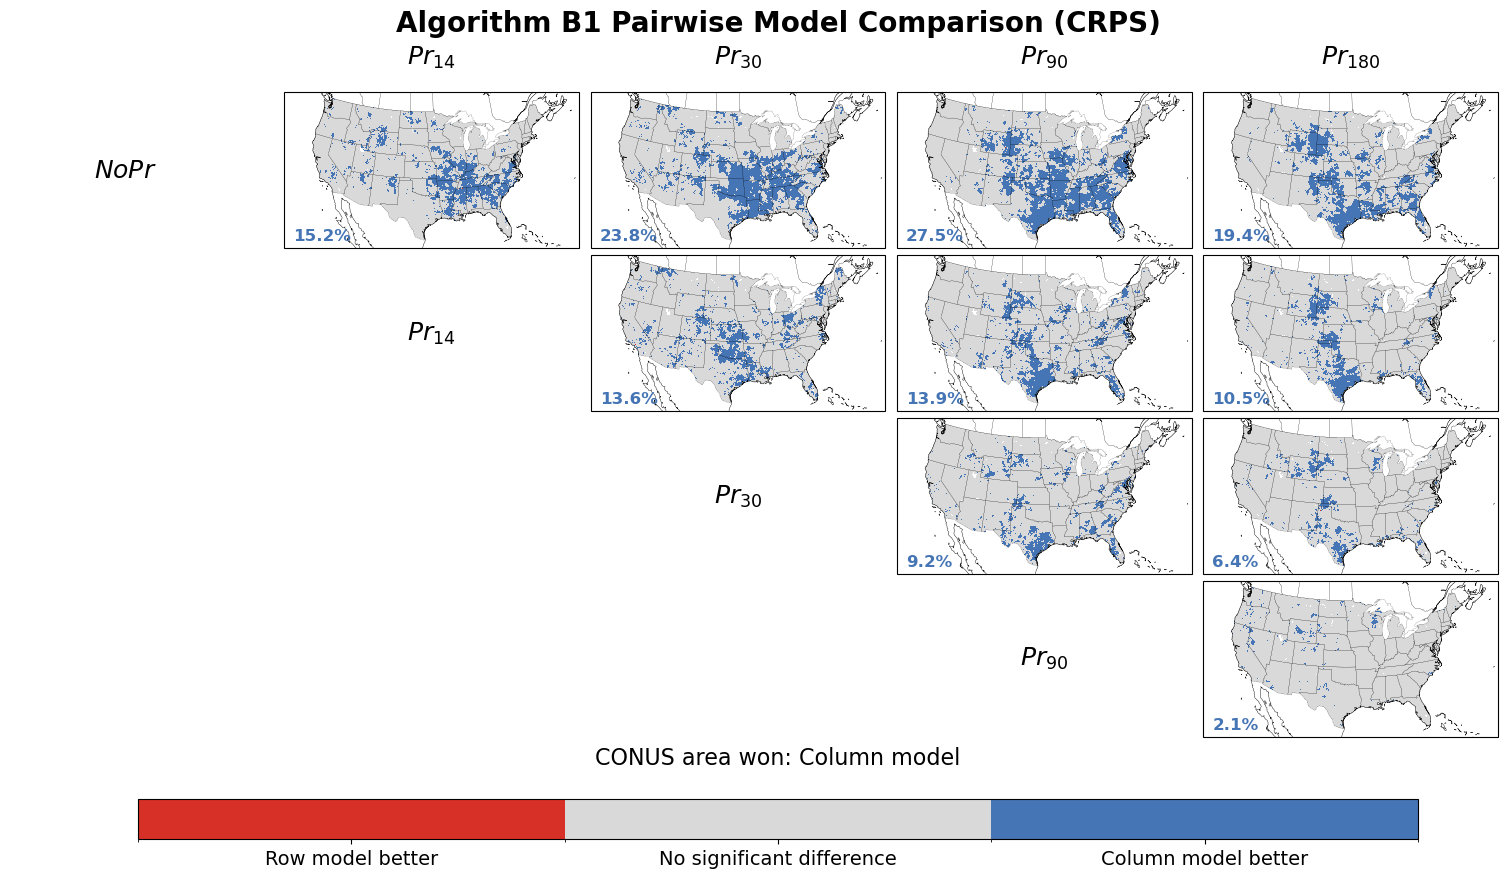

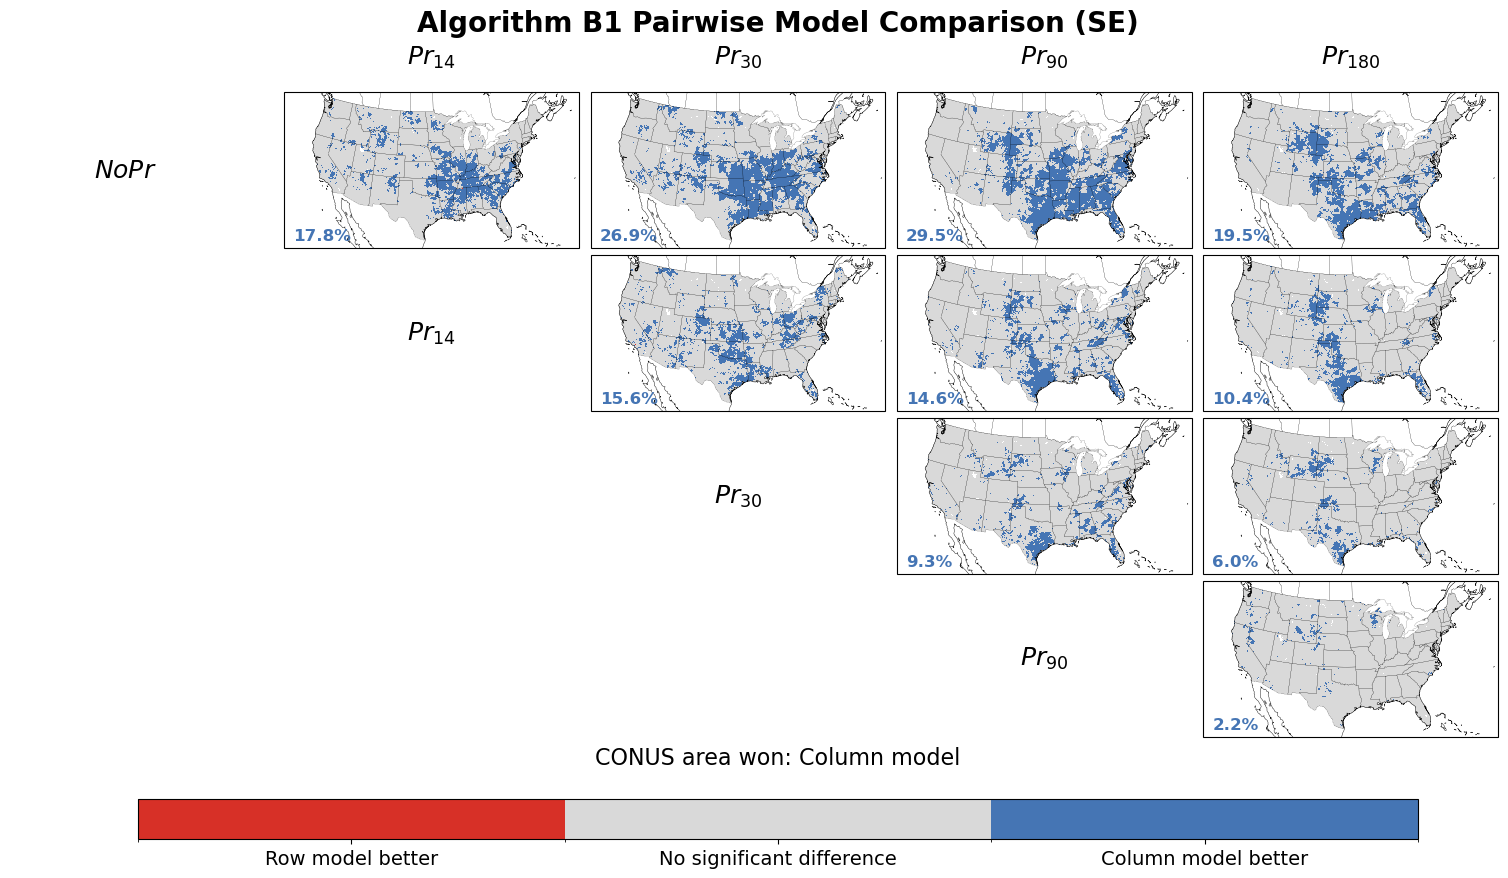

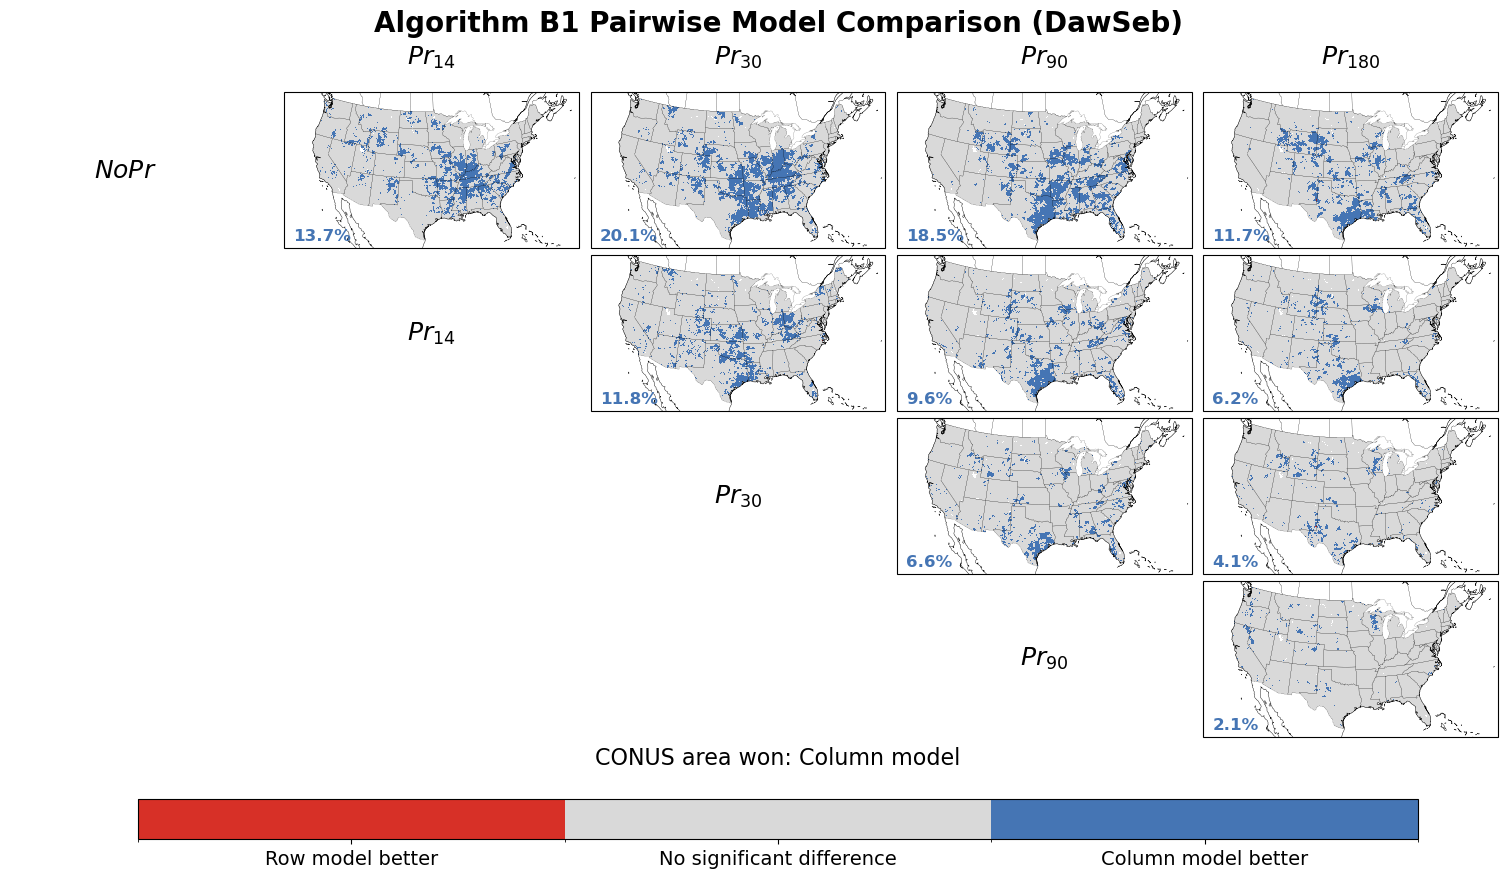

In [8]:
for metric in ["CRPS_cv", "SE_cv","DawSeb_cv"]:# ,"DawSeb_cv", "SE_cv"
    fig = plot_algorithmB1_matrix(metric=metric, datasets=datasets,b1_files=b1_files,models=models, alpha=0.05,proj=proj,state_borders=state_borders,rivers=None)
    plt.show()

*Figure. Pairwise Algorithm B1 comparisons of competing precipitation covariates. Blue shading indicates locations where the column model significantly outperforms the row model ($p \le 0.05$); red shading indicates locations where the row model significantly outperforms the column model; gray indicates no statistically significant difference. Percentages reported within each panel correspond to the fraction of the CONUS area where the column model is significantly preferred.*

In [9]:
model_ids = {"PrNO": 1,"Pr14": 2,"Pr30": 3,"Pr90": 4,"Pr180": 5}

## Dominant Precipitation Covariate Based on Predictive Skill
While pairwise comparisons identify significant differences between individual model pairs, a synthesis is required to determine the overall preferred precipitation covariate at each location.

For a given metric, each model receives one victory for every statistically significant pairwise comparison in which its score is lower than that of its competitor. The number of significant victories is then accumulated across all competing models. Models with the greatest number of victories become candidates for dominance.

When multiple candidates achieve the same number of significant victories, the tie is resolved using the average score itself, with preference given to the model having the lowest mean score. Locations where no model achieves a statistically significant victory are classified as No Winner.

In [10]:
def dominant_model_map(metric,datasets, b1_files, models, alpha=0.05):
    """
    Dominant model based on pairwise Algorithm B1 tests.
    Returns
    1. Count significant pairwise victories (Algorithm B1).
    2. Model(s) with the most wins become candidates.
    3. If several candidates are tied, select the candidate with
       the lowest mean score.
    4. If no model achieves any significant victory, assign 0.
    -------
    dominant :  xr.DataArray(dtype=str)
    """
    metric_name = metric.replace("_cv", "")
    # --------------------------------------------------
    # Mean metric scores
    # --------------------------------------------------
    scores = xr.concat([datasets[m][metric].mean("time") for m in models],dim="model")
    scores = scores.assign_coords(model=models)    
    wins = xr.zeros_like(scores, dtype=np.int16)
    # --------------------------------------------------
    # Count pairwise victories
    # --------------------------------------------------
    for i, model_i in enumerate(models):
        score_i = datasets[model_i][metric].mean("time")
        for j, model_j in enumerate(models):
            if j <= i:
                continue
            score_j = datasets[model_j][metric].mean("time")
            pair = (model_i, model_j)
            ds_b1 = b1_files[pair]
            pval = ds_b1[f"{metric_name}_B1_pvalue"]
            sig = pval <= alpha
            i_wins = sig & (score_i < score_j)
            j_wins = sig & (score_j < score_i)
            wins.loc[dict(model=model_i)] += i_wins.astype(np.int16)
            wins.loc[dict(model=model_j)] += j_wins.astype(np.int16)
    # --------------------------------------------------
    # Determine candidates
    # --------------------------------------------------
    max_wins = wins.max("model")
    candidates = wins == max_wins
    # score used for non-candidates
    dummy_score = float(scores.max( skipna=True) ) + 1
    candidate_scores = xr.where(candidates,  scores, dummy_score)
    # replace remaining NaNs (all-NaN locations)
    candidate_scores = candidate_scores.fillna(dummy_score)
    # tied candidate with lowest score wins
    dominant = candidate_scores.argmin("model").astype(np.int16) + 1
    # no winner if nobody achieved a significant victory
    dominant = xr.where( max_wins == 0, 0,dominant  )
    # --------------------------------------------------
    # Metadata
    # --------------------------------------------------
    dominant.attrs["long_name"] = ( f"Dominant model ({metric_name})")
    dominant.attrs["flag_values"] = ([0] + list(range(1, len(models) + 1)))
    dominant.attrs["flag_meanings"] = ("NoWin " + " ".join(models))

    return dominant

In [11]:
dominant_CRPS = dominant_model_map("CRPS_cv",datasets,b1_files,models,alpha=0.05)
dominant_DawSeb = dominant_model_map("DawSeb_cv",datasets,b1_files,models,alpha=0.05)
dominant_SE = dominant_model_map("SE_cv",datasets,b1_files,models,alpha=0.05)

In [12]:
dom_stack = xr.concat([dominant_CRPS,dominant_DawSeb,dominant_SE],dim="metric")

In [13]:
from scipy.stats import mode
def majority_vote(x):
    x = x[x > 0]
    if len(x) == 0:
        return 0
    vals, counts = np.unique(x, return_counts=True)
    if counts.max() < 2:
        return 0
    return vals[counts.argmax()]

def majority_vote_no_nothing(x):
    """
    Majority vote among valid model selections.
    Assumes:
        0 = NoWin
    Returns:
        NaN if no consensus.
    """
    x = x[x > 0]
    if len(x) == 0:
        return np.nan
    vals, counts = np.unique(x, return_counts=True)
    max_count = counts.max()
    winners = vals[counts == max_count]
    # tie among winners
    if len(winners) > 1:
        return np.nan
    return winners[0]

def agreement_count(x):
    # remove no-winner class
    x = x[x > 0]
    if len(x) == 0:
        return 0
    vals, counts = np.unique( x, return_counts=True )
    return counts.max()

In [14]:
consensus_map = xr.apply_ufunc(majority_vote,dom_stack,input_core_dims=[["metric"]],vectorize=True,output_dtypes=[int])
agreement_map = xr.apply_ufunc(agreement_count,dom_stack,input_core_dims=[["metric"]],vectorize=True,output_dtypes=[np.int16])
agreement_map = agreement_map.where(landmask)
consensus_map = consensus_map.where(landmask)

In [15]:
def plot_categorical_map(da, title,cmap,norm,cbar_labels,ax=None, proj=None,state_borders=None,rivers=None,\
                    show_colorbar=True,show_percentages=True,extent=(-125, -66.5, 24, 50)):
    """
    Generic categorical map plotting function.
    Parameters
    ----------
    da : xr.DataArray
        Categorical map.
    title : str
    cmap : matplotlib colormap
    norm : matplotlib.colors.BoundaryNorm
    cbar_labels : list of str
        Labels corresponding to categories.
    ax : matplotlib axis, optional
    show_colorbar : bool, default=True
    show_percentages : bool, default=True
        Display area-weighted percentages.
    """
    # --------------------------------------------------
    # Figure / Axis
    # --------------------------------------------------
    created_fig = False
    if ax is None:
        fig = plt.figure(figsize=(13, 7))
        ax = plt.axes(projection=proj)
        created_fig = True
    else:
        fig = ax.figure
    da.plot(ax=ax, transform=ccrs.PlateCarree(),cmap=cmap, norm=norm, add_colorbar=False)
    # --------------------------------------------------
    # Map features
    # --------------------------------------------------
    ax.coastlines(linewidth=0.3)
    if state_borders is not None:
        ax.add_feature( state_borders, edgecolor="k",linewidth=0.1,zorder=100)
    if rivers is not None:
        ax.add_feature(rivers, edgecolor="royalblue",linewidth=0.2)
    ax.set_extent( extent,crs=ccrs.PlateCarree() )
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')
    # --------------------------------------------------
    # Area percentages
    # --------------------------------------------------
    if show_percentages:
        lat_name = ( "lat"if "lat" in da.coords else "latitude")
        weights = np.cos(np.deg2rad(da[lat_name]))

        total_area = weights.where( np.isfinite(da)).sum().item()
        txt = []
        for iclass, label in enumerate(cbar_labels):
            pct = ( 100 * (da == iclass).weighted(weights).sum().item()/ total_area)
            txt.append(f"{label.replace(chr(10),' ')}: {pct:.1f}%")

        ax.text(0.02,0.02, "\n".join(txt), transform=ax.transAxes,fontsize=11,fontweight="bold",va="bottom", ha="left",bbox=dict(facecolor="white",alpha=0.85,edgecolor="none"))
    # --------------------------------------------------
    # Colorbar
    # --------------------------------------------------
    if show_colorbar:
        ticks = (np.diff(norm.boundaries)/2+ norm.boundaries[:-1])
        cbar = plt.colorbar( plt.cm.ScalarMappable(  cmap=cmap,norm=norm,),ax=ax,orientation="horizontal",pad=0.06,shrink=0.85,ticks=ticks)
        cbar.ax.set_xticklabels(cbar_labels)
        cbar.ax.tick_params(labelsize=12)
        cbar.set_label( "Consensus dominant precipitation covariate",fontsize=14)
    # --------------------------------------------------
    # Title
    # --------------------------------------------------
    ax.set_title(title, fontsize=18,fontweight="bold")

    return fig,ax

## Preferred Precipitation Covariate from Cross-Validated CRPS
The primary model-selection result is based on CRPS because CRPS is a proper scoring rule that evaluates the full predictive distribution and is generally regarded as the most comprehensive measure of probabilistic forecast performance. The dominant-covariate map below therefore represents the primary precipitation-covariate recommendation.

(<Figure size 1300x700 with 2 Axes>,
 <GeoAxes: title={'center': 'Dominant Model (CRPS)'}>)

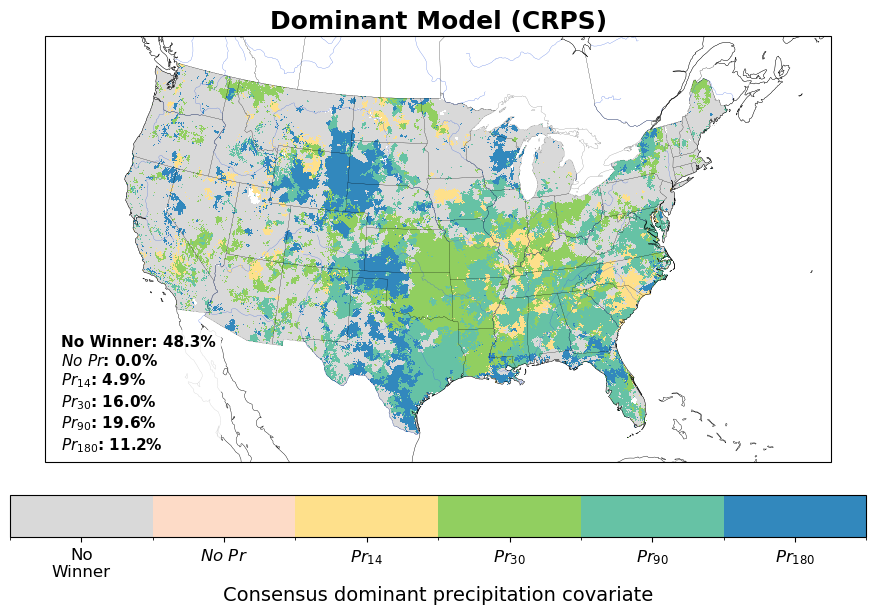

In [16]:
dominant_cmap = mcolors.ListedColormap([
    "#d9d9d9",
    "#fddbc7",
    "#fee08b",
   # "#d9ef8b",
    "#91cf60",
    "#66c2a5",
    "#3288bd",
])
dominant_labels = [
    "No\nWinner",
    "$No$ $Pr$",
    "$Pr_{14}$",
    "$Pr_{30}$",
    #"$Pr_{45}$",
    "$Pr_{90}$",
    "$Pr_{180}$",
]

dominant_norm = mcolors.BoundaryNorm(np.arange(-0.5, len(dominant_labels) + 0.5, 1), dominant_cmap.N,)

plot_categorical_map( dominant_CRPS.where(landmask),title="Dominant Model (CRPS)", cmap=dominant_cmap,norm=dominant_norm, cbar_labels=dominant_labels, proj=proj,state_borders=state_borders,rivers=rivers)

*Figure. Dominant precipitation covariate identified from cross-validated CRPS. At each grid cell, the selected covariate corresponds to the model with the greatest number of significant Algorithm B1 victories. Ties are resolved using the lowest mean CRPS. Gray indicates locations where no model achieves a statistically significant advantage.*

## Agreement Among Predictive Performance Metrics
Model-selection conclusions can depend on the metric used to evaluate predictive performance. To assess the robustness of the dominant-covariate classification, agreement is evaluated across three complementary predictive metrics: CRPS, Dawid-Sebastiani score, and squared error.

Agreement among metrics provides a measure of confidence in the selected precipitation covariate. Regions where multiple metrics identify the same dominant covariate indicate that model preference is relatively insensitive to the choice of verification metric.

(<Figure size 1300x700 with 2 Axes>,
 <GeoAxes: title={'center': 'Agreement Among CRPS, Dawid-Sebastiani, and Squared Error'}>)

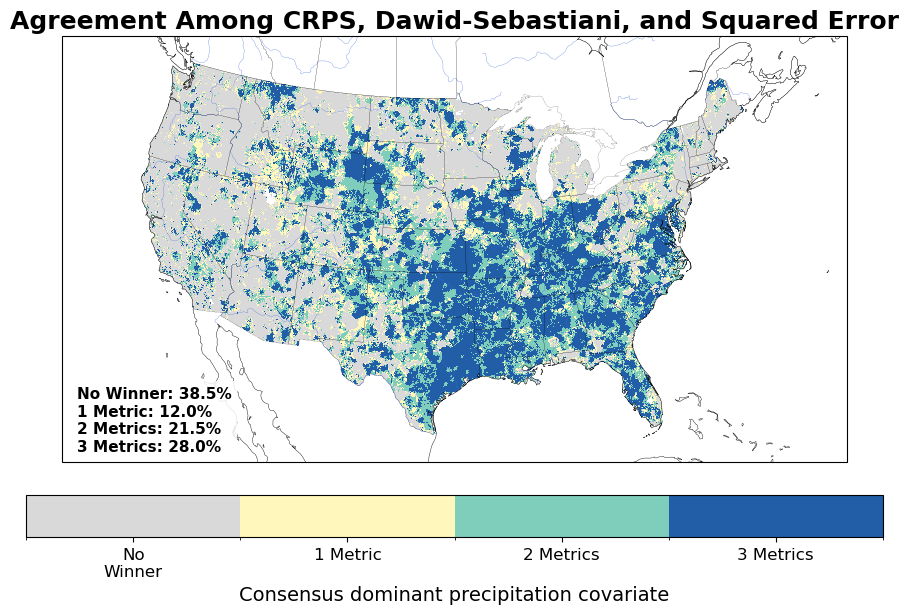

In [17]:
agreement_cmap = mcolors.ListedColormap(["#d9d9d9",  # No winner
    "#fff7bc",  # 1 metric
    "#7fcdbb",  # 2 metrics
    "#225ea8"])

agreement_norm = mcolors.BoundaryNorm( [-0.5, 0.5, 1.5, 2.5, 3.5], agreement_cmap.N)

agreement_labels = ["No\nWinner",
    "1 Metric",
    "2 Metrics",
    "3 Metrics"]

plot_categorical_map(agreement_map.where(landmask), title="Agreement Among CRPS, Dawid-Sebastiani, and Squared Error",\
    cmap=agreement_cmap, norm=agreement_norm, cbar_labels=agreement_labels,proj=proj,state_borders=state_borders,rivers=rivers)

#Figure. Agreement among CRPS, Dawid-Sebastiani score, and squared error. Values indicate the number of predictive metrics selecting the same dominant precipitation covariate at each grid cell. Greater agreement implies increased confidence that the identified precipitation accumulation period represents a robust improvement in predictive performance.#

## Information-Theoretic Model Selection
Predictive metrics quantify out-of-sample prediction skill, whereas information criteria evaluate model fit while penalizing model complexity. To investigate whether conclusions based on predictive verification are consistent with likelihood-based model selection, dominant-covariate maps are also constructed using the minimum Akaike Information Criterion (AIC) and Bayesian Information Criterion (BIC).

Unlike the predictive-skill analysis, these classifications are based solely on model fit and do not incorporate Algorithm B1 significance testing.

In [18]:
def dominant_model_minimum( metric, datasets, models,landmask):
    """
    Dominant model based solely on minimum metric value.
    Used for AIC and BIC.
    """
    scores = xr.concat([datasets[m][metric]for m in models],dim="model")
    scores = scores.assign_coords( model=models)
    dummy_score = float(np.nanmax(scores.values)) + 1
    scores = scores.fillna(dummy_score)
    dominant = scores.argmin("model").astype(np.int16) + 1
    dominant = dominant.where(landmask,  0)

    dominant.attrs["long_name"] = (f"Best model ({metric})")
    dominant.attrs["flag_values"] = ([0] + list(range(1, len(models)+1)))
    dominant.attrs["flag_meanings"] = ( "NoWin " + " ".join(models))

    return dominant

In [19]:
dominant_AIC = dominant_model_minimum( "AIC",datasets, models,landmask)
dominant_BIC = dominant_model_minimum("BIC",datasets,models,landmask)

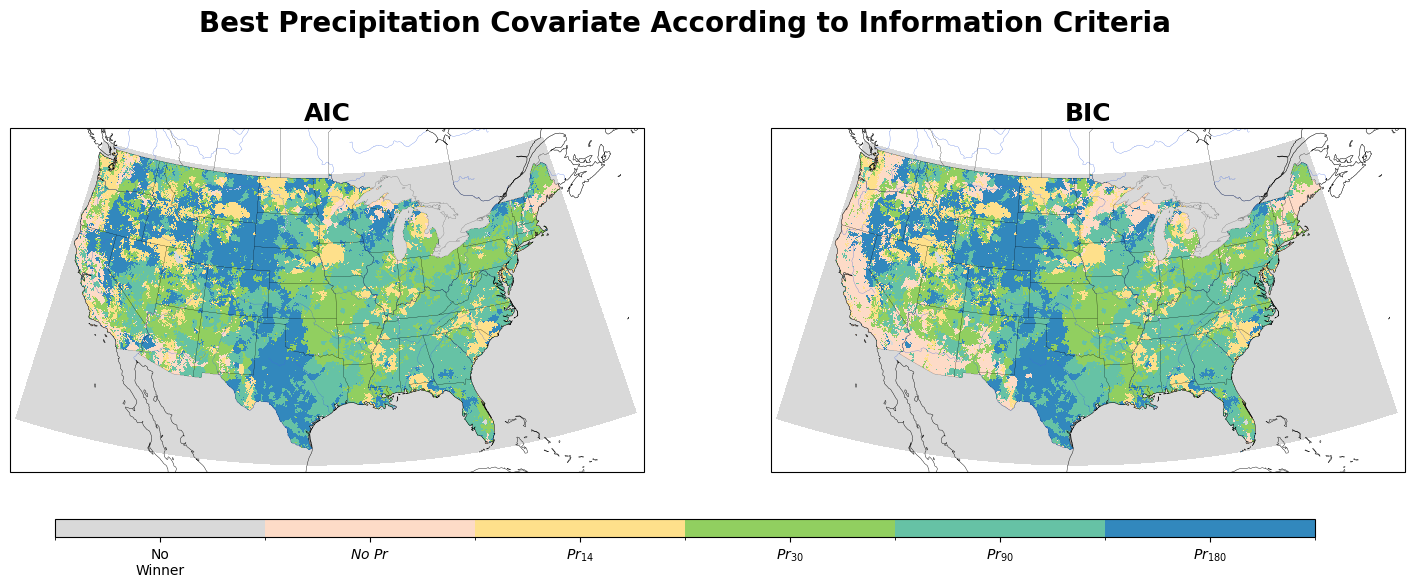

In [20]:
fig, axes = plt.subplots( 1, 2,figsize=(18, 6),subplot_kw={"projection": proj})

plot_categorical_map( dominant_AIC, title="AIC", cmap=dominant_cmap, norm=dominant_norm, cbar_labels=dominant_labels, ax=axes[0],
    state_borders=state_borders, rivers=rivers, show_colorbar=False, show_percentages=False)

plot_categorical_map( dominant_BIC, title="BIC", cmap=dominant_cmap, norm=dominant_norm, cbar_labels=dominant_labels, ax=axes[1],
    state_borders=state_borders, rivers=rivers, show_colorbar=False, show_percentages=False)

cax = fig.add_axes([0.15, 0.10, 0.70, 0.03])
ticks = ( np.diff(dominant_norm.boundaries) / 2 + dominant_norm.boundaries[:-1])
cb = fig.colorbar(plt.cm.ScalarMappable(cmap=dominant_cmap,norm=dominant_norm), cax=cax, orientation="horizontal", ticks=ticks)

cb.ax.set_xticklabels(dominant_labels)
plt.suptitle("Best Precipitation Covariate According to Information Criteria", fontsize=20, fontweight="bold")
plt.show()

*Figure. Dominant precipitation covariate according to information criteria. Panels show the precipitation covariate associated with the minimum AIC (left) and minimum BIC (right) at each grid cell. These information-theoretic classifications provide an independent assessment of preferred precipitation accumulation periods based on model fit and complexity.*

## Agreement Between Cross-Validated CRPS and Information Criteria
CRPS is used as the primary model-selection metric because it evaluates the full predictive distribution and provides a comprehensive measure of out-of-sample predictive performance. To assess whether conclusions based on predictive skill are supported by traditional model-selection criteria, the dominant precipitation covariate identified from CRPS is compared against a consensus classification derived from AIC and BIC.

Agreement between these independent approaches suggests that the selected precipitation covariate improves both predictive skill and overall model fit. Disagreement highlights locations where models that optimize forecasting performance differ from those favored by information-theoretic criteria.

In [21]:
ic_stack = xr.concat([dominant_AIC,dominant_BIC,],dim="metric")
ic_consensus = xr.apply_ufunc( majority_vote_no_nothing,ic_stack, input_core_dims=[["metric"]],vectorize=True, output_dtypes=[float])

In [22]:
crps_vs_ic = xr.where(np.isfinite(ic_consensus), dominant_CRPS == ic_consensus, np.nan)
crps_vs_ic = crps_vs_ic.where(landmask)
crps_vs_ic = xr.where(crps_vs_ic,1,0,)

(<Figure size 1300x700 with 2 Axes>,
 <GeoAxes: title={'center': 'CRPS vs AIC/BIC Agreement'}>)

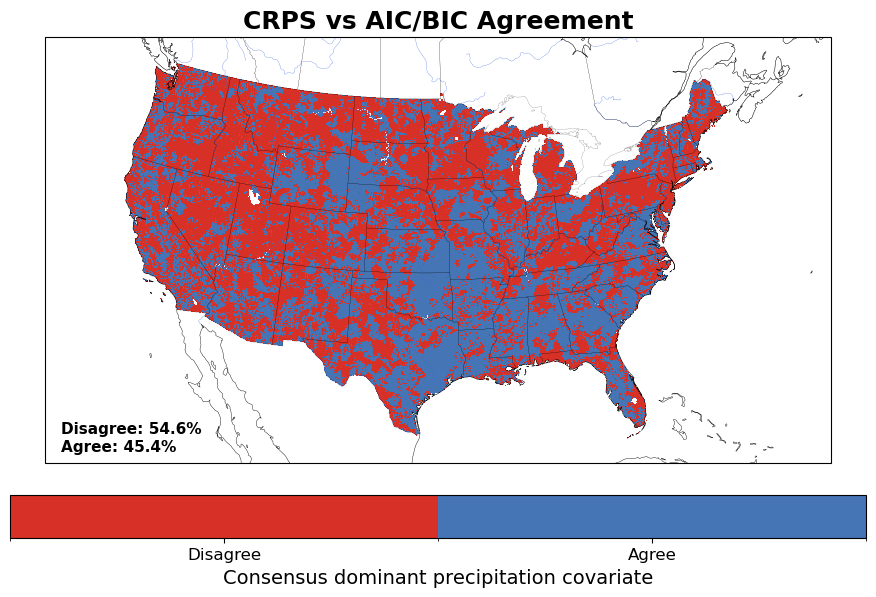

In [23]:
compare_cmap = mcolors.ListedColormap([
    "#d73027",  # disagreement
    "#4575b4",  # agreement
])
compare_norm = mcolors.BoundaryNorm([-0.5, 0.5, 1.5],compare_cmap.N)
compare_labels = ["Disagree","Agree"]
plot_categorical_map( crps_vs_ic.where(landmask),title="CRPS vs AIC/BIC Agreement",
    cmap=compare_cmap,norm=compare_norm,cbar_labels=compare_labels,proj=proj,state_borders=state_borders,rivers=rivers)

*Figure. Agreement between cross-validated CRPS and information-theoretic model selection. Blue regions indicate locations where the dominant precipitation covariate identified from CRPS matches the consensus covariate selected by AIC and BIC. Red regions indicate disagreement between predictive-skill-based and likelihood-based model selection. Agreement suggests that the preferred precipitation accumulation period improves both out-of-sample predictive performance and in-sample model fit.*

############################################################################
## Not from me and didn't check anything yet. I will do that tomorrow.
############################################################################

(<Figure size 1300x700 with 2 Axes>,
 <GeoAxes: title={'center': 'Dominant Model (CRPS)'}>)

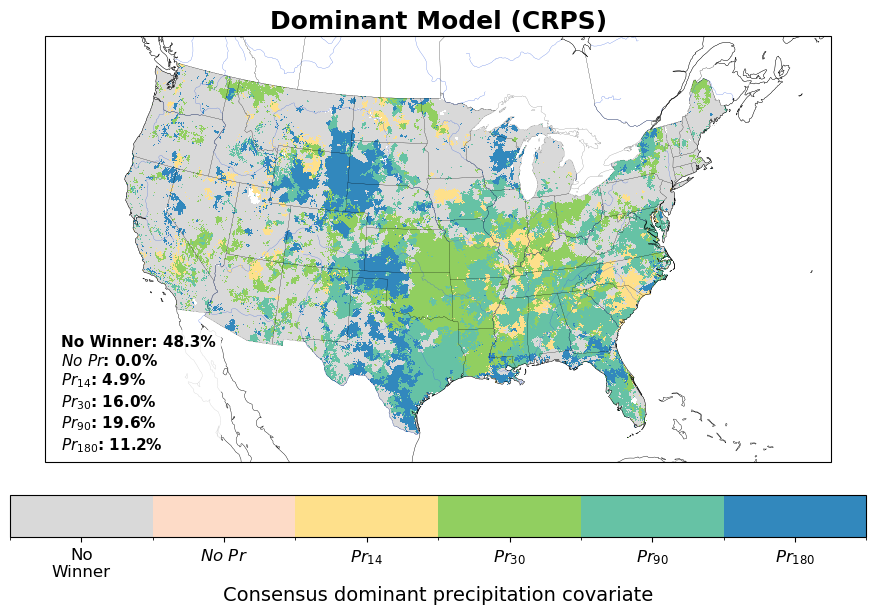

In [24]:
plot_categorical_map( dominant_CRPS.where(landmask),title="Dominant Model (CRPS)", cmap=dominant_cmap,norm=dominant_norm, cbar_labels=dominant_labels, proj=proj,state_borders=state_borders,rivers=rivers)

# Figure 6. Dominant Precipitation Covariate and Mean Annual Precipitation
Hypothesis: Regions with higher climatological precipitation favor longer precipitation accumulation periods because of increased hydroclimatic memory.

In [25]:
dsmean = xr.open_dataset('/Volumes/Data/CMIP6_Large_Ensembles/NClimGrid/AnnualMean/prcp_mean_annual_nclimgrid.nc')
prcp_mean = dsmean['prcp'].load()
dsmean.close()

In [26]:
dsmean = xr.open_dataset('/Volumes/Data/CMIP6_Large_Ensembles/NClimGrid/AnnualMean/prcp_mean_DJF_nclimgrid.nc')
prcp_djf = dsmean['prcp_djf_mean'].load()
dsmean.close()

In [ ]:
dssm = xr.open_dataset('/Volumes/Data/NCEI_Drought_Indices/ERA5_Land_Data/Monthly/ERA5_Land_CONUS_soil_moisture_layers1-4.nc')
dssm = dssm.sel(valid_time=slice('1952-01-01','2025-12-31'))
#swvl1 = dssm["swvl1"].mean("valid_time")
#swvl2 = dssm["swvl2"].mean("valid_time")
swvl3 = dssm["swvl3"].mean("valid_time")
#swvl4 = dssm["swvl4"].mean("valid_time")
dssm.close()


In [ ]:
#swvl1 = swvl1.interp(longitude=dominant_CRPS.lon,latitude=dominant_CRPS.lat,method='linear')
#swvl2 = swvl2.interp(longitude=dominant_CRPS.lon,latitude=dominant_CRPS.lat,method='linear')
swvl3 = swvl3.interp(longitude=dominant_CRPS.lon,latitude=dominant_CRPS.lat,method='linear')
#swvl4 = swvl4.interp(longitude=dominant_CRPS.lon,latitude=dominant_CRPS.lat,method='linear')

In [ ]:
#dsout = swvl1.to_dataset(name='swvl1')
#dsout = dsout.merge({'swvl2':swvl2,'swvl3':swvl3,'swvl4':swvl4})
#dsout.to_netcdf('/Users/gahe5417/data/TXx/ERA5_Land_CONUS_soil_moisture_layer14_mean_1952_2025_gridNClimGrid.nc')

In [ ]:
sm_mean = swvl3


In [ ]:
print("Fetching stable topography data array...")
topo_file_path = ensaio.fetch_earth_topography(version=1)
dstopo = xr.load_dataset(topo_file_path)
topo = dstopo['topography'].sel(longitude=slice(-125, -66.5),latitude=slice(24.4,49.4))
# Extract spatial variables (Ensaio uses standard 'longitude', 'latitude', and 'topography')
lonz = topo.longitude.values
latz = topo.latitude.values
z = topo.values
topo_regrid = topo.interp(longitude=dominant_CRPS.lon,latitude=dominant_CRPS.lat)



In [30]:
classes = { 0: ("NoWin",  np.nan),
    1: ("NoPr",   0),
    2: ("Pr14",  14),
    3: ("Pr30",  30),
    4: ("Pr90",  90),
    5: ("Pr180", 180),
}
order = [
    "NoWin",
    "NoPr",
    "Pr14",
    "Pr30",
    "Pr90",
    "Pr180",
]
colors = [
    "#d9d9d9",
    "#fddbc7",
    "#fee08b",
    "#d9ef8b",
    "#66c2a5",
    "#3288bd",
]
colors_tercile = {
    "NoWin": "#d9d9d9",
    "NoPr":"#fddbc7",
    "Pr14": "#fee08b",
    "Pr30": "#d9ef8b",
    "Pr90": "#66c2a5",
    "Pr180": "#3288bd",
}

In [31]:
records = []

for iclass, (label, period) in classes.items():
    vals = ( prcp_mean.where(dominant_CRPS.where(landmask) == iclass).values.ravel())
    vals = vals[np.isfinite(vals)]
    records.append( pd.DataFrame({"class": iclass, "label": label,"period": period,"ppt": vals}))

df = pd.concat(records, ignore_index=True)

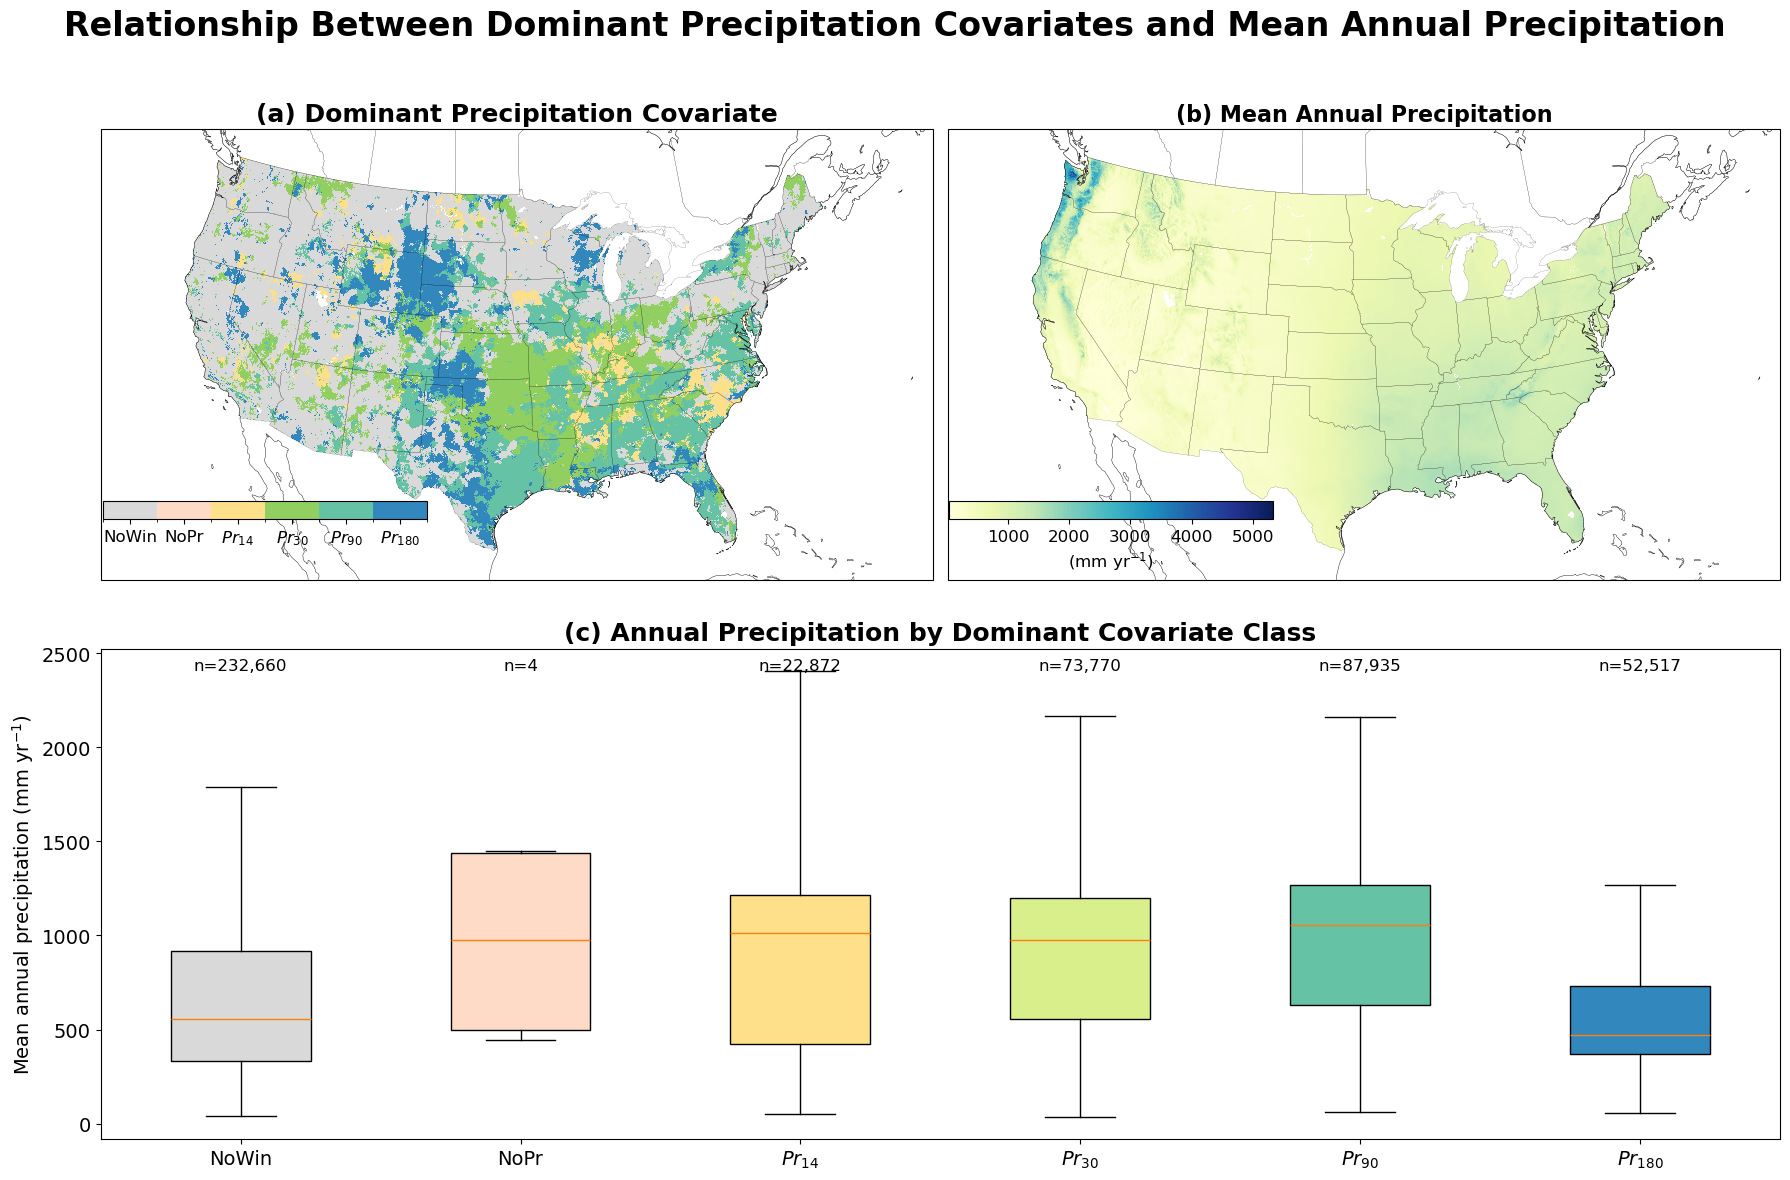

In [32]:

data = [df.loc[df["label"] == label, "ppt"]for label in order]
# --------------------------------------------------
# Figure layout
# --------------------------------------------------
fig = plt.figure(figsize=(18, 12))
plt.subplots_adjust(left=0.05,right=0.95,bottom=0.1,top=0.95,hspace=0.1,wspace=0.04)
gs = GridSpec(2,2,figure=fig,height_ratios=[1, 0.8])
# ==================================================
# (a) Dominant covariate
# ==================================================
ax1 = fig.add_subplot(gs[0, 0],projection=proj)

im_a = plot_categorical_map(dominant_CRPS.where(landmask),title="(a) Dominant Precipitation Covariate",cmap=dominant_cmap,norm=dominant_norm,cbar_labels=dominant_labels,ax=ax1,\
    state_borders=state_borders,rivers=None,show_colorbar=False,show_percentages=False,)
# --------------------------------------------------
# Colorbar for panel (a)
# --------------------------------------------------
cax_dom = fig.add_axes( [0.06, 0.555, 0.18, 0.015])
ticks = (np.diff(dominant_norm.boundaries) / 2+ dominant_norm.boundaries[:-1])
cb_dom = fig.colorbar(plt.cm.ScalarMappable(cmap=dominant_cmap,norm=dominant_norm),cax=cax_dom,orientation="horizontal",ticks=ticks)
cb_dom.ax.set_xticklabels([ "NoWin","NoPr", r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$"])
cb_dom.ax.tick_params(labelsize=12)
cb_dom.set_label("",fontsize=12)
# ==================================================
# (b) Annual precipitation map
# ==================================================
ax2 = fig.add_subplot(gs[0, 1],projection=proj)
im_p = prcp_mean.where(landmask).plot(ax=ax2,transform=ccrs.PlateCarree(),cmap="YlGnBu",add_colorbar=False)
ax2.coastlines(linewidth=0.3)

if state_borders is not None:
    ax2.add_feature( state_borders,edgecolor="k",linewidth=0.1,zorder=100)
ax2.set_extent((-125, -66.5, 24, 50),crs=ccrs.PlateCarree())

ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.set_title("(b) Mean Annual Precipitation",fontsize=16,fontweight="bold",)
# --------------------------------------------------
# precipitation colorbar
# --------------------------------------------------
cax_p = fig.add_axes([0.53, 0.555, 0.18, 0.015])
cb_p = fig.colorbar(im_p,cax=cax_p,orientation="horizontal")
cb_p.ax.tick_params(labelsize=12)
cb_p.set_label(r"(mm yr$^{-1}$)",fontsize=12)

# ==================================================
# (c) Boxplot
# ==================================================
ax3 = fig.add_subplot(gs[1, :])

data = [df.loc[df["label"] == label,"ppt"]for label in order]
bp = ax3.boxplot(data,tick_labels=["NoWin","NoPr",r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$",],showfliers=False,patch_artist=True,)

for box, color in zip(bp["boxes"],colors):
    box.set_facecolor(color)
ax3.set_ylabel(r"Mean annual precipitation (mm yr$^{-1}$)",fontsize=14)
ax3.set_title("(c) Annual Precipitation by Dominant Covariate Class",fontsize=18,fontweight="bold")
ax3.tick_params(axis="both",labelsize=14)
# sample size labels
for i, label in enumerate(order, start=1):
    n = (df["label"] == label).sum()
    ax3.text( i,ax3.get_ylim()[1] * 0.98,f"n={n:,}",ha="center",va="top",fontsize=12)

fig.suptitle("Relationship Between Dominant Precipitation Covariates and Mean Annual Precipitation",fontsize=24,fontweight="bold",)
plt.tight_layout()
plt.show()

*Figure 6. Relationship between dominant precipitation covariates and mean annual precipitation. (a) Dominant precipitation covariate identified from cross-validated CRPS using pairwise Algorithm B1 comparisons. At each grid cell, the selected covariate corresponds to the model with the greatest number of significant pairwise victories, with ties resolved using the lowest mean CRPS. (b) Mean annual precipitation climatology derived from NClimGrid daily precipitation observations. (c) Distribution of mean annual precipitation associated with each dominant-covariate class; sample sizes are indicated above each boxplot. Regions classified as NoWin generally occur in areas receiving lower annual precipitation than regions where precipitation covariates improve predictive skill. However, the preferred accumulation periods (($Pr_{14}$), ($Pr_{30}$), ($Pr_{90}$), and ($Pr_{180}$)) exhibit substantial overlap in their precipitation distributions, indicating that precipitation amount alone does not explain the dominant precipitation-memory timescale. The comparatively low annual precipitation associated with ($Pr_{180}$) suggests that long accumulation periods may be most relevant in moisture-limited environments where precipitation deficits evolve over seasonal timescales.*

## Figure 7. Dominant Precipitation Covariate and Elevation
Hypothesis: Topographic controls weaken the influence of precipitation accumulation period on heat extremes.

In [39]:

records = []
for iclass, (label, period) in classes.items():
    vals = topo_regrid.where(dominant_CRPS.where(landmask) == iclass).values.ravel()
    vals = vals[np.isfinite(vals)]
    records.append( pd.DataFrame({"class": iclass, "label": label,"period": period,"elev": vals}))    
df = pd.concat(records, ignore_index=True)

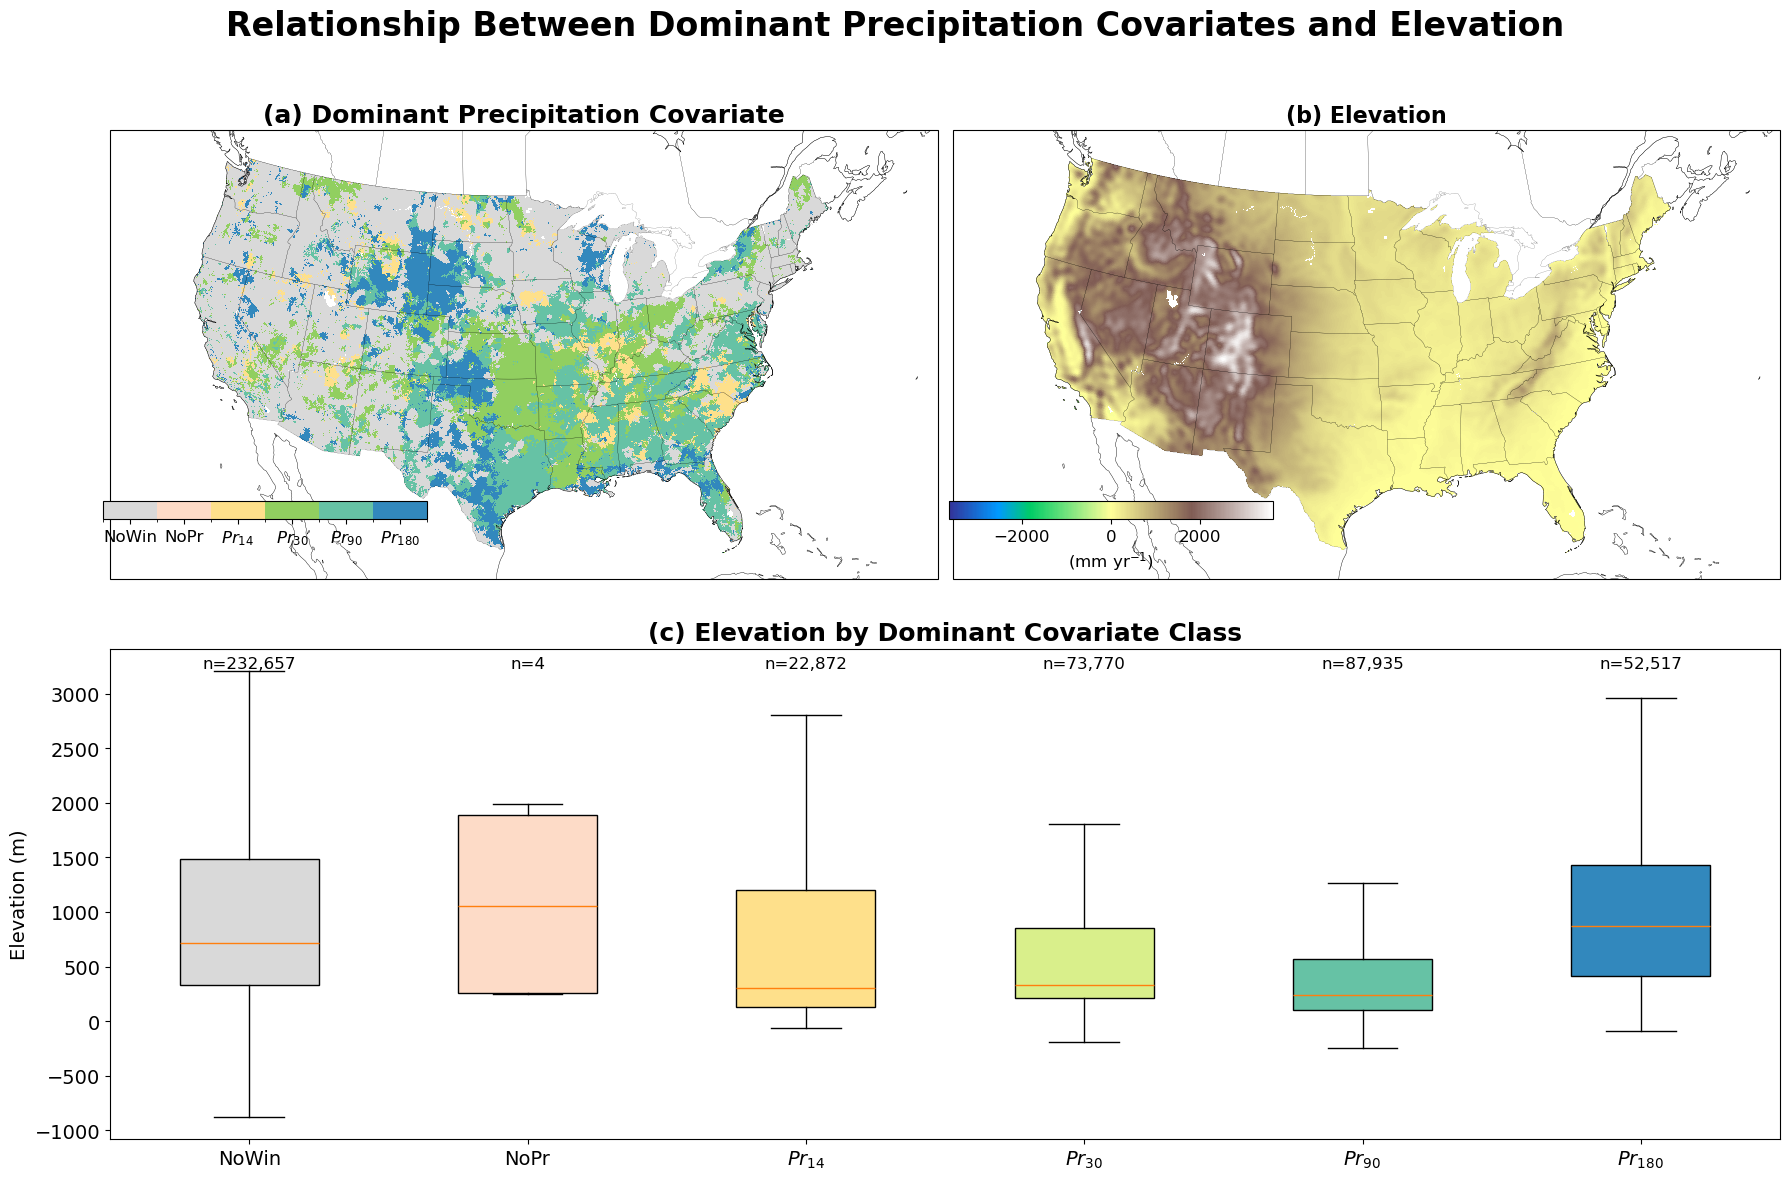

In [40]:
data = [df.loc[df["label"] == label, "elev"]for label in order]
# --------------------------------------------------
# Figure layout
# --------------------------------------------------
fig = plt.figure(figsize=(18, 12))
plt.subplots_adjust(left=0.05,right=0.95,bottom=0.1,top=0.95,hspace=0.1,wspace=0.04)
gs = GridSpec(2,2,figure=fig,height_ratios=[1, 0.8])
# ==================================================
# (a) Dominant covariate
# ==================================================
ax1 = fig.add_subplot(gs[0, 0],projection=proj)

im_a = plot_categorical_map(dominant_CRPS.where(landmask),title="(a) Dominant Precipitation Covariate",cmap=dominant_cmap,norm=dominant_norm,cbar_labels=dominant_labels,ax=ax1,\
    state_borders=state_borders,rivers=None,show_colorbar=False,show_percentages=False,)
# --------------------------------------------------
# Colorbar for panel (a)
# --------------------------------------------------
cax_dom = fig.add_axes( [0.06, 0.555, 0.18, 0.015])
ticks = (np.diff(dominant_norm.boundaries) / 2+ dominant_norm.boundaries[:-1])
cb_dom = fig.colorbar(plt.cm.ScalarMappable(cmap=dominant_cmap,norm=dominant_norm),cax=cax_dom,orientation="horizontal",ticks=ticks)
cb_dom.ax.set_xticklabels([ "NoWin","NoPr", r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$"])
cb_dom.ax.tick_params(labelsize=12)
cb_dom.set_label("",fontsize=12)
# ==================================================
# (b) Annual precipitation map
# ==================================================
ax2 = fig.add_subplot(gs[0, 1],projection=proj)
im_p = topo_regrid.where(landmask).plot(ax=ax2,transform=ccrs.PlateCarree(),cmap="terrain",add_colorbar=False)
ax2.coastlines(linewidth=0.3)

if state_borders is not None:
    ax2.add_feature( state_borders,edgecolor="k",linewidth=0.1,zorder=100)
ax2.set_extent((-125, -66.5, 24, 50),crs=ccrs.PlateCarree())

ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.set_title("(b) Elevation",fontsize=16,fontweight="bold",)
# --------------------------------------------------
# precipitation colorbar
# --------------------------------------------------
cax_p = fig.add_axes([0.53, 0.555, 0.18, 0.015])
cb_p = fig.colorbar(im_p,cax=cax_p,orientation="horizontal")
cb_p.ax.tick_params(labelsize=12)
cb_p.set_label(r"(mm yr$^{-1}$)",fontsize=12)

# ==================================================
# (c) Boxplot
# ==================================================
ax3 = fig.add_subplot(gs[1, :])

data = [df.loc[df["label"] == label,"elev"]for label in order]
bp = ax3.boxplot(data,tick_labels=["NoWin","NoPr",r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$",],showfliers=False,patch_artist=True,)

for box, color in zip(bp["boxes"],colors):
    box.set_facecolor(color)
ax3.set_ylabel(r"Elevation (m)",fontsize=14)
ax3.set_title("(c) Elevation by Dominant Covariate Class",fontsize=18,fontweight="bold")
ax3.tick_params(axis="both",labelsize=14)
# sample size labels
for i, label in enumerate(order, start=1):
    n = (df["label"] == label).sum()
    ax3.text( i,ax3.get_ylim()[1] * 0.98,f"n={n:,}",ha="center",va="top",fontsize=12)

fig.suptitle("Relationship Between Dominant Precipitation Covariates and Elevation",fontsize=24,fontweight="bold",)
plt.tight_layout()
plt.show()

*Figure 7. Relationship between dominant precipitation covariates and elevation. (a) Dominant precipitation covariate identified from cross-validated CRPS using pairwise Algorithm B1 comparisons. At each grid cell, the selected covariate corresponds to the model with the greatest number of significant pairwise victories, with ties resolved using the lowest mean CRPS. (b) Topography of the continental United States. (c) Distribution of elevation associated with each dominant-covariate class; sample sizes are indicated above each boxplot. Elevation exhibits a clearer relationship with dominant precipitation accumulation period than mean annual precipitation. Regions classified as NoWin are concentrated in areas of complex terrain and generally occur at higher elevations than regions favoring ($Pr_{30}$) or ($Pr_{90}$). The ($Pr_{90}$) class is most strongly associated with low-elevation regions, particularly across the Gulf Coast, southeastern United States, and lower Mississippi Valley, whereas ($Pr_{180}$) occurs more frequently in higher-elevation environments of the western and central United States. These patterns suggest that topography and associated hydrologic processes, including snow storage, seasonal recharge, and moisture persistence, may influence the precipitation-memory timescale most relevant to extreme warm-temperature variability.*

In [ ]:
weights = np.cos(np.deg2rad(dominant_CRPS.lat))
total_area = weights.where(np.isfinite(dominant_CRPS.where(landmask))).sum().item()

fractions = {}
for iclass, label in classes.items():
    area = (dominant_CRPS.where(landmask) == iclass).weighted(weights).sum().item()
    fractions[label] = 100 * area / total_area
for k, v in fractions.items():
    print(f"{k:6s}: {v:.1f}%")

NoWin : 48.3%
NoPr  : 0.0%
Pr14  : 4.9%
Pr30  : 16.0%
Pr90  : 19.6%
Pr180 : 11.2%


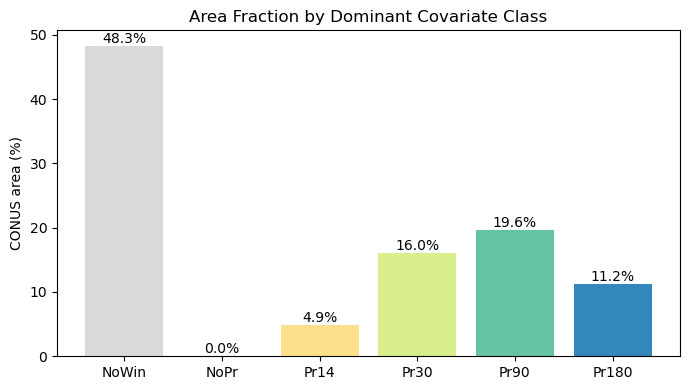

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(fractions.keys(),fractions.values(),color=colors)
ax.set_ylabel("CONUS area (%)")
ax.set_title("Area Fraction by Dominant Covariate Class")

for i, val in enumerate(fractions.values()):
    ax.text(i,val + 0.5,f"{val:.1f}%",ha="center",)

plt.tight_layout()
plt.show()

In [ ]:
records = []

for iclass, label in classes.items():
    vals = prcp_djf.where(dominant_CRPS.where(landmask) == iclass).values.ravel()
    vals = vals[np.isfinite(vals)]
    records.append( pd.DataFrame({"class": iclass, "label": label,"ppt": vals}))

df = pd.concat(records, ignore_index=True)

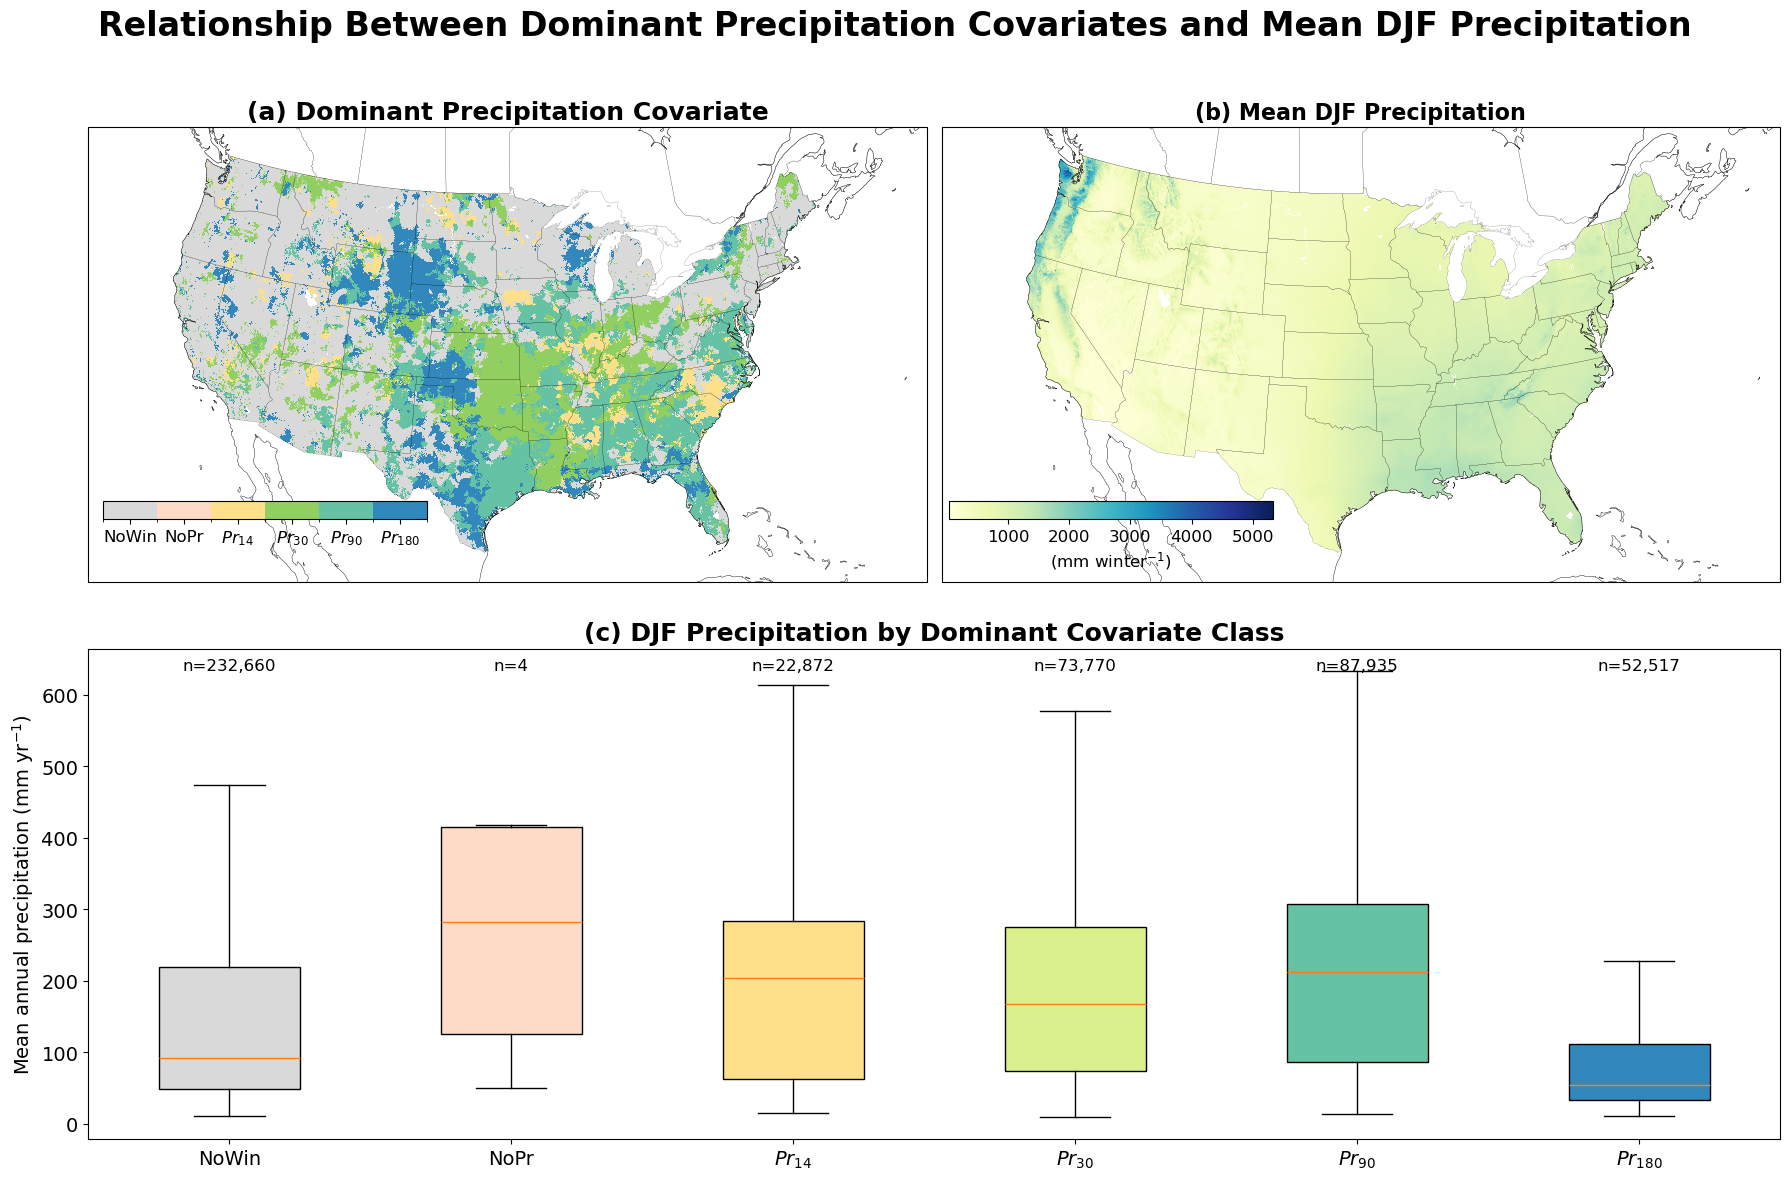

In [ ]:

data = [df.loc[df["label"] == label, "ppt"]for label in order]
# --------------------------------------------------
# Figure layout
# --------------------------------------------------
fig = plt.figure(figsize=(18, 12))
plt.subplots_adjust(left=0.05,right=0.95,bottom=0.1,top=0.95,hspace=0.1,wspace=0.04)
gs = GridSpec(2,2,figure=fig,height_ratios=[1, 0.8])
# ==================================================
# (a) Dominant covariate
# ==================================================
ax1 = fig.add_subplot(gs[0, 0],projection=proj)

im_a = plot_categorical_map(dominant_CRPS.where(landmask),title="(a) Dominant Precipitation Covariate",cmap=dominant_cmap,norm=dominant_norm,cbar_labels=dominant_labels,ax=ax1,\
    state_borders=state_borders,rivers=None,show_colorbar=False,show_percentages=False,)
# --------------------------------------------------
# Colorbar for panel (a)
# --------------------------------------------------
cax_dom = fig.add_axes( [0.06, 0.555, 0.18, 0.015])
ticks = (np.diff(dominant_norm.boundaries) / 2+ dominant_norm.boundaries[:-1])
cb_dom = fig.colorbar(plt.cm.ScalarMappable(cmap=dominant_cmap,norm=dominant_norm),cax=cax_dom,orientation="horizontal",ticks=ticks)
cb_dom.ax.set_xticklabels([ "NoWin","NoPr", r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$"])
cb_dom.ax.tick_params(labelsize=12)
cb_dom.set_label("",fontsize=12)
# ==================================================
# (b) Annual precipitation map
# ==================================================
ax2 = fig.add_subplot(gs[0, 1],projection=proj)
im_p = prcp_mean.where(landmask).plot(ax=ax2,transform=ccrs.PlateCarree(),cmap="YlGnBu",add_colorbar=False)
ax2.coastlines(linewidth=0.3)

if state_borders is not None:
    ax2.add_feature( state_borders,edgecolor="k",linewidth=0.1,zorder=100)
ax2.set_extent((-125, -66.5, 24, 50),crs=ccrs.PlateCarree())

ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.set_title("(b) Mean DJF Precipitation",fontsize=16,fontweight="bold",)
# --------------------------------------------------
# precipitation colorbar
# --------------------------------------------------
cax_p = fig.add_axes([0.53, 0.555, 0.18, 0.015])
cb_p = fig.colorbar(im_p,cax=cax_p,orientation="horizontal")
cb_p.ax.tick_params(labelsize=12)
cb_p.set_label(r"(mm winter$^{-1}$)",fontsize=12)

# ==================================================
# (c) Boxplot
# ==================================================
ax3 = fig.add_subplot(gs[1, :])

data = [df.loc[df["label"] == label,"ppt"]for label in order]
bp = ax3.boxplot(data,tick_labels=["NoWin","NoPr",r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$",],showfliers=False,patch_artist=True,)

for box, color in zip(bp["boxes"],colors):
    box.set_facecolor(color)
ax3.set_ylabel(r"Mean annual precipitation (mm yr$^{-1}$)",fontsize=14)
ax3.set_title("(c) DJF Precipitation by Dominant Covariate Class",fontsize=18,fontweight="bold")
ax3.tick_params(axis="both",labelsize=14)
# sample size labels
for i, label in enumerate(order, start=1):
    n = (df["label"] == label).sum()
    ax3.text( i,ax3.get_ylim()[1] * 0.98,f"n={n:,}",ha="center",va="top",fontsize=12)

fig.suptitle("Relationship Between Dominant Precipitation Covariates and Mean DJF Precipitation",fontsize=24,fontweight="bold",)
plt.tight_layout()
plt.show()

*Figure 8. Relationship between dominant precipitation covariates and mean winter (DJF) precipitation. (a) Dominant precipitation covariate identified from cross-validated CRPS using pairwise Algorithm B1 comparisons. (b) Mean winter (December-February) precipitation climatology derived from NClimGrid daily precipitation observations. (c) Distribution of mean winter precipitation associated with each dominant-covariate class; sample sizes are indicated above each boxplot. Winter precipitation exhibits a clearer relationship with dominant precipitation accumulation period than annual precipitation. Regions dominated by ($Pr_{90}$) generally occur in areas receiving substantial winter precipitation, particularly across the southeastern United States and Gulf Coast, whereas ($Pr_{180}$) is associated with comparatively dry winter climates. The results suggest that seasonal moisture recharge and hydroclimatic persistence may be more important controls on precipitation-memory timescales than annual precipitation amount alone.*

In [ ]:
# --------------------------------------------------
# Elevation terciles
# --------------------------------------------------
z = topo_regrid.where(landmask)
q1 = z.quantile(1/3).item()
q2 = z.quantile(2/3).item()
print(f"Low elevation    : z < {q1:.0f} m")
print(f"Medium elevation : {q1:.0f} ≤ z < {q2:.0f} m")
print(f"High elevation   : z ≥ {q2:.0f} m")
terciles = { "Low": z < q1,"Medium": (z >= q1) & (z < q2),"High": z >= q2,}
# --------------------------------------------------
# Area fractions by tercile
# --------------------------------------------------
weights = np.cos(np.deg2rad(dominant_CRPS.lat))
results = []
for tercile_name, tercile_mask in terciles.items():
    total_area = weights.where(tercile_mask).sum().item()
    for iclass, label in classes.items():
        area = ((dominant_CRPS == iclass) & tercile_mask).weighted(weights).sum().item()
        frac = 100 * area / total_area
        results.append({ "Elevation": tercile_name,  "Class": label, "Fraction": frac,})
df_frac = pd.DataFrame(results)
print(df_frac.pivot( index="Class",  columns="Elevation",values="Fraction",).round(1))

Low elevation    : z < 302 m
Medium elevation : 302 ≤ z < 968 m
High elevation   : z ≥ 968 m
Elevation  High   Low  Medium
Class                        
NoPr        0.0   0.0     0.0
NoWin      60.2  30.3    55.3
Pr14        4.0   7.4     3.2
Pr180      14.6   6.8    12.5
Pr30       11.2  20.9    15.7
Pr90        9.9  34.7    13.3


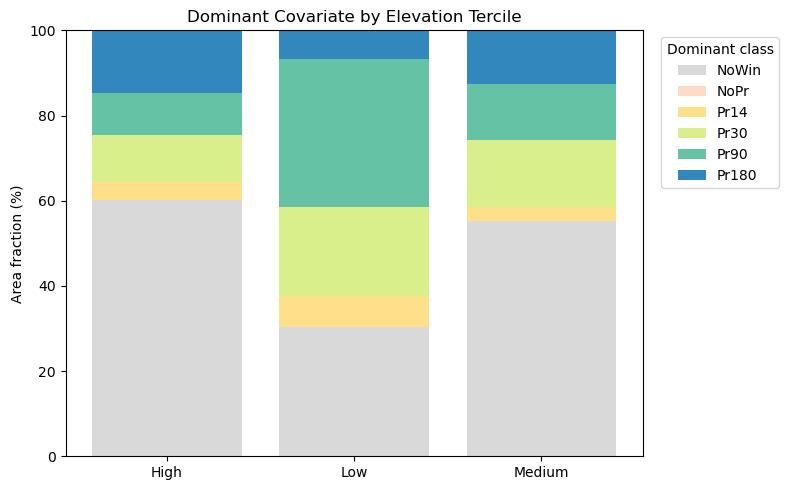

In [ ]:
pivot = df_frac.pivot(index="Elevation",columns="Class",values="Fraction",)

pivot = pivot[order]
fig, ax = plt.subplots(figsize=(8, 5))
bottom = np.zeros(len(pivot))
for cls in order:
    ax.bar(pivot.index,pivot[cls],bottom=bottom,label=cls,color=colors_tercile[cls])
    bottom += pivot[cls]
ax.set_ylim(0, 100)
ax.set_ylabel("Area fraction (%)")
ax.set_title("Dominant Covariate by Elevation Tercile")
ax.legend(title="Dominant class",bbox_to_anchor=(1.02, 1),loc="upper left",)
plt.tight_layout()
plt.show()

*Figure 9. Dependence of dominant precipitation-covariate classes on elevation. Area-weighted fractions of the continental United States assigned to each dominant precipitation-covariate class within low-, medium-, and high-elevation terciles. The fraction of grid cells classified as NoWin increases substantially with elevation, indicating that precipitation accumulation period becomes a weaker determinant of model performance in complex terrain. In contrast, the prevalence of ($Pr_{90}$) decreases strongly with elevation, whereas ($Pr_{180}$) becomes more common at higher elevations. These results suggest that topography influences the characteristic hydroclimatic memory timescale associated with extreme temperatures and that long accumulation periods may be related to moisture-storage processes operating over seasonal timescales in elevated regions.*

In [41]:

records = []
for iclass, (label, period) in classes.items():
    vals = sm_mean.where(dominant_CRPS.where(landmask) == iclass).values.ravel()
    vals = vals[np.isfinite(vals)]
    records.append( pd.DataFrame({"class": iclass, "label": label,"soil_moisture": vals}))    
df = pd.concat(records, ignore_index=True)

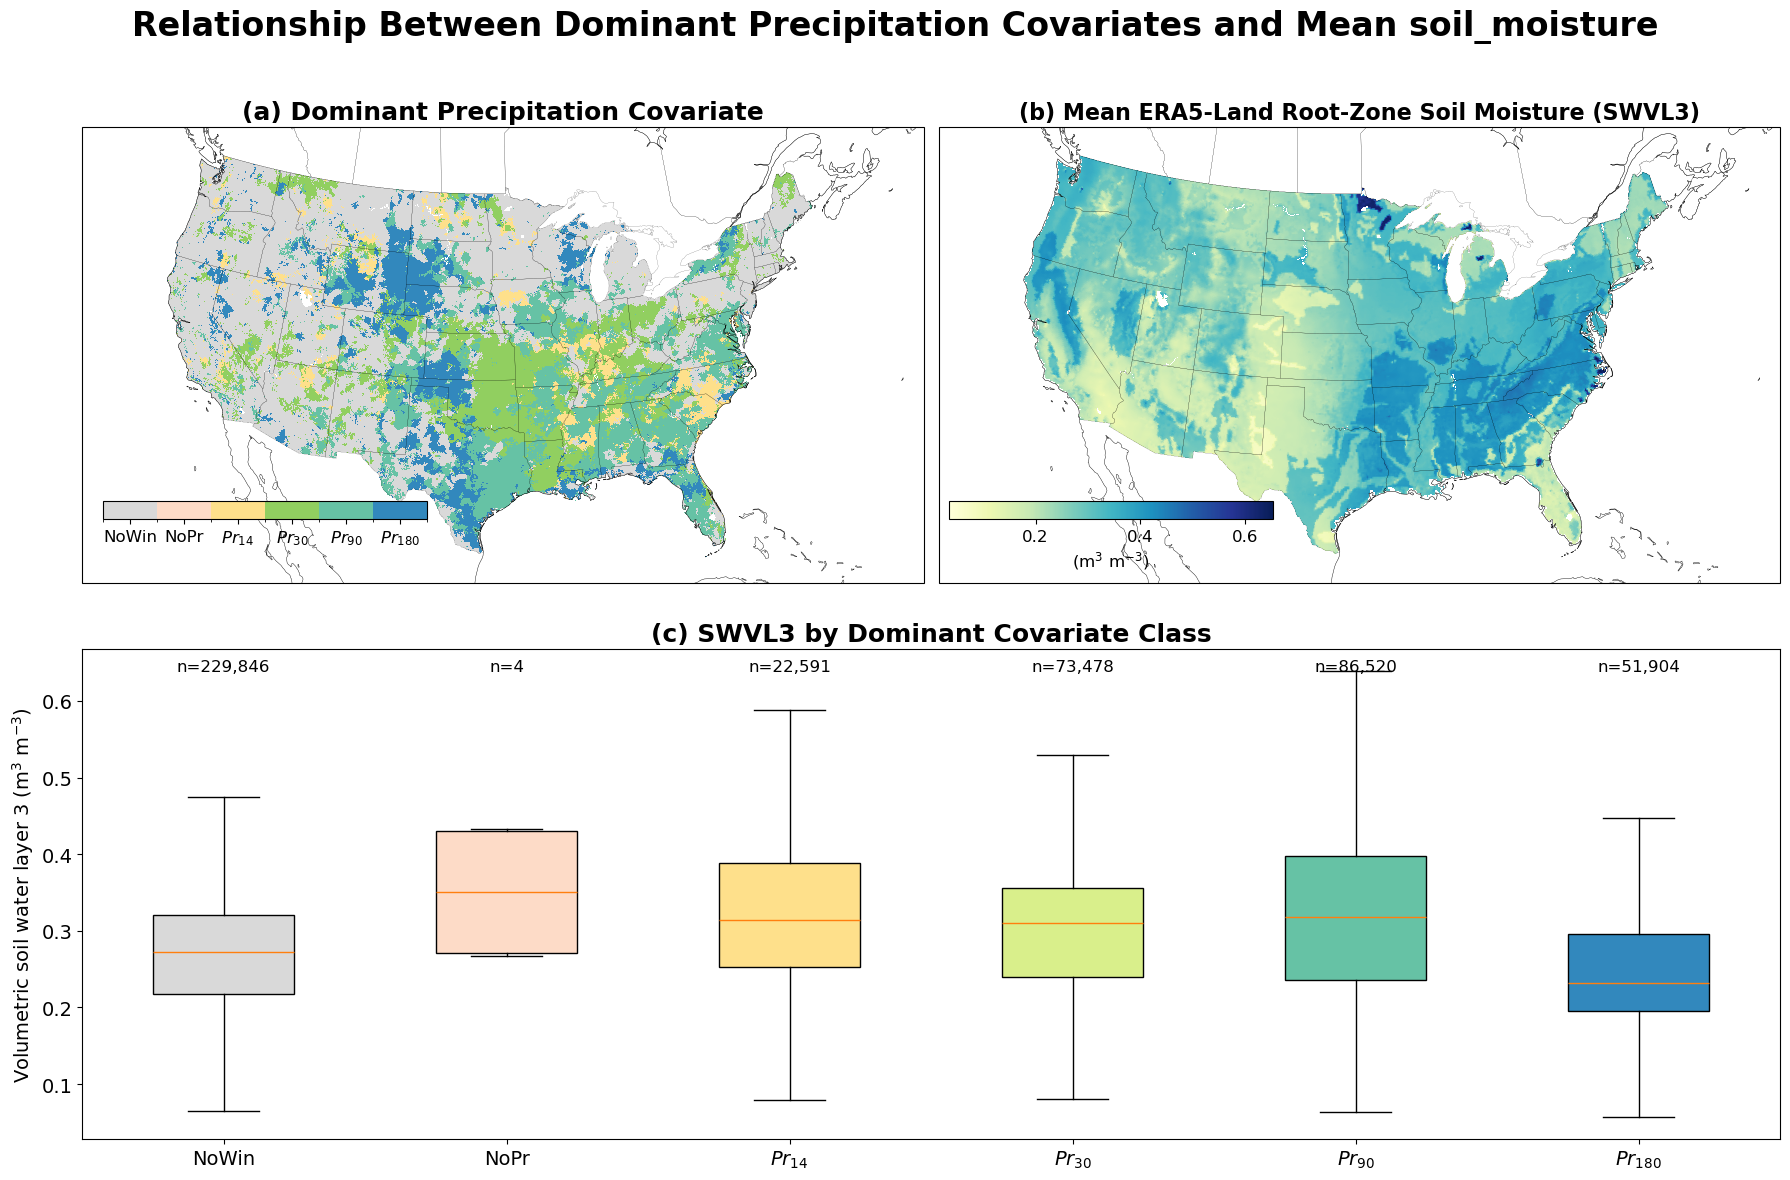

In [47]:

data = [df.loc[df["label"] == label, "soil_moisture"]for label in order]
# --------------------------------------------------
# Figure layout
# --------------------------------------------------
fig = plt.figure(figsize=(18, 12))
plt.subplots_adjust(left=0.05,right=0.95,bottom=0.1,top=0.95,hspace=0.1,wspace=0.04)
gs = GridSpec(2,2,figure=fig,height_ratios=[1, 0.8])
# ==================================================
# (a) Dominant covariate
# ==================================================
ax1 = fig.add_subplot(gs[0, 0],projection=proj)

im_a = plot_categorical_map(dominant_CRPS.where(landmask),title="(a) Dominant Precipitation Covariate",cmap=dominant_cmap,norm=dominant_norm,cbar_labels=dominant_labels,ax=ax1,\
    state_borders=state_borders,rivers=None,show_colorbar=False,show_percentages=False,)
# --------------------------------------------------
# Colorbar for panel (a)
# --------------------------------------------------
cax_dom = fig.add_axes( [0.06, 0.555, 0.18, 0.015])
ticks = (np.diff(dominant_norm.boundaries) / 2+ dominant_norm.boundaries[:-1])
cb_dom = fig.colorbar(plt.cm.ScalarMappable(cmap=dominant_cmap,norm=dominant_norm),cax=cax_dom,orientation="horizontal",ticks=ticks)
cb_dom.ax.set_xticklabels([ "NoWin","NoPr", r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$"])
cb_dom.ax.tick_params(labelsize=12)
cb_dom.set_label("",fontsize=12)
# ==================================================
# (b) Annual precipitation map
# ==================================================
ax2 = fig.add_subplot(gs[0, 1],projection=proj)
im_p = sm_mean.where(landmask).plot(ax=ax2,transform=ccrs.PlateCarree(),cmap="YlGnBu",add_colorbar=False)
ax2.coastlines(linewidth=0.3)

if state_borders is not None:
    ax2.add_feature( state_borders,edgecolor="k",linewidth=0.1,zorder=100)
ax2.set_extent((-125, -66.5, 24, 50),crs=ccrs.PlateCarree())

ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.set_title("(b) Mean ERA5-Land Root-Zone Soil Moisture (SWVL3)",fontsize=16,fontweight="bold",)
# --------------------------------------------------
# precipitation colorbar
# --------------------------------------------------
cax_p = fig.add_axes([0.53, 0.555, 0.18, 0.015])
cb_p = fig.colorbar(im_p,cax=cax_p,orientation="horizontal")
cb_p.ax.tick_params(labelsize=12)
cb_p.set_label(r"(m$^{3}$ m$^{-3}$)",fontsize=12)

# ==================================================
# (c) Boxplot
# ==================================================
ax3 = fig.add_subplot(gs[1, :])

data = [df.loc[df["label"] == label,"soil_moisture"]for label in order]
bp = ax3.boxplot(data,tick_labels=["NoWin","NoPr",r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$",],showfliers=False,patch_artist=True,)

for box, color in zip(bp["boxes"],colors):
    box.set_facecolor(color)
ax3.set_ylabel(r"Volumetric soil water layer 3 (m$^{3}$ m$^{-3}$)",fontsize=14)
ax3.set_title("(c) SWVL3 by Dominant Covariate Class",fontsize=18,fontweight="bold")
ax3.tick_params(axis="both",labelsize=14)
# sample size labels
for i, label in enumerate(order, start=1):
    n = (df["label"] == label).sum()
    ax3.text( i,ax3.get_ylim()[1] * 0.98,f"n={n:,}",ha="center",va="top",fontsize=12)

fig.suptitle("Relationship Between Dominant Precipitation Covariates and Mean soil_moisture",fontsize=24,fontweight="bold",)
plt.tight_layout()
plt.show()

*Figure 10. Relationship between dominant precipitation covariates and mean root\-zone soil moisture. (a) Dominant precipitation covariate identified from cross\-validated CRPS using pairwise Algorithm B1 comparisons. At each grid cell, the selected covariate corresponds to the model with the greatest number of significant pairwise victories, with ties resolved using the lowest mean CRPS. (b) Mean ERA5\-Land volumetric soil water content in layer 3 (SWVL3; 28\-100 cm depth), representing moisture conditions within the root zone. (c) Distribution of mean SWVL3 associated with each dominant\-covariate class; sample sizes are indicated above each boxplot. Root\-zone soil moisture exhibits a clearer relationship with dominant precipitation accumulation period than annual or winter precipitation alone. Regions dominated by ($Pr_{90}$) generally correspond to relatively moist environments characterized by high winter precipitation and low elevations, whereas ($Pr_{180}$) is associated with lower root\-zone soil moisture and higher\-elevation regions. The results suggest that the preferred precipitation accumulation period reflects differences in hydroclimatic memory and subsurface moisture storage, supporting the interpretation that soil\-moisture persistence plays an important role in modulating extreme warm\-temperature variability across the continental United States.*

## Hydroclimatic Controls on Dominant Precipitation Accumulation Periods

Figures 6-10 suggest that the preferred precipitation accumulation period is controlled more by hydroclimatic memory and topographic setting than by precipitation amount alone.

Annual and winter precipitation (Figures 6 and 8) distinguish regions where precipitation covariates improve predictive skill from regions classified as *NoWin*, but they provide limited separation among the dominant accumulation periods themselves. In particular, $Pr_{14}$, $Pr_{30}$, and $Pr_{90}$ exhibit substantial overlap in both annual and winter precipitation distributions, indicating that precipitation amount alone does not explain the preferred accumulation timescale.

Topography exhibits a much stronger relationship with dominant covariate selection (Figures 7 and 9). The occurrence of *NoWin* increases with elevation, while $Pr_{90}$ becomes progressively less common. In contrast, $Pr_{180}$ is preferentially associated with higher-elevation regions, suggesting that longer precipitation-memory timescales may be linked to snow storage, seasonal recharge, or other slow hydrologic processes.

The soil-moisture analysis (Figure 10) provides the clearest physical signal. Regions dominated by $Pr_{90}$ are generally characterized by relatively moist soils, whereas $Pr_{180}$ tends to occur in environments with lower root-zone soil moisture and higher elevations. These patterns suggest that the dominant precipitation accumulation period reflects differences in land-surface moisture storage and persistence rather than precipitation totals alone.

Overall, the results indicate that the preferred precipitation accumulation period is most closely related to hydroclimatic memory, antecedent soil-moisture conditions, and topographic controls. Low-elevation regions with relatively moist soils tend to favor seasonal accumulation periods $Pr_{90}$, whereas higher-elevation and moisture-limited environments more frequently favor longer accumulation periods $Pr_{180}$.



## Figure 11 

In [81]:
records = []

for iclass, (label, period) in classes.items():
    elev = topo_regrid.where(dominant_CRPS.where(landmask) == iclass).values.ravel()
    sm = sm_mean.where(dominant_CRPS == iclass).values.ravel()
    valid = np.isfinite(elev) & np.isfinite(sm)
    records.append(pd.DataFrame({"class": iclass,"label": label,"elevation": elev[valid],"swvl3": sm[valid],}))
df_env = pd.concat(records,ignore_index=True,)

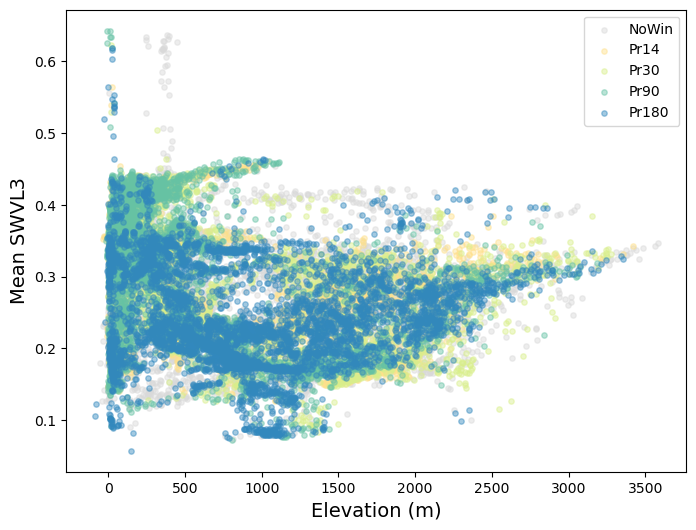

In [ ]:
colors_map = {
    "NoWin": "#d9d9d9",
    "Pr14": "#fee08b",
    "Pr30": "#d9ef8b",
    "Pr90": "#66c2a5",
    "Pr180": "#3288bd",
}
fig, ax = plt.subplots(figsize=(8, 6))

for label in ["NoWin","Pr14","Pr30","Pr90","Pr180"]:
    dfi = df_env[df_env["label"] == label]
    idx = np.random.choice(len(dfi),min(5000, len(dfi)),replace=False,)
    ax.scatter(dfi.iloc[idx]["elevation"],dfi.iloc[idx]["swvl3"],s=15,alpha=0.45,color=colors_map[label],label=label,)
ax.hexbin(
    elevation,
    swvl3,
    gridsize=40,
    cmap="viridis",
    mincnt=1,
)
ax.set_xlabel("Elevation (m)",fontsize=14)
ax.set_ylabel("Mean SWVL3",fontsize=14)
ax.tick_params(axis="both",labelsize=14)

ax.legend()
plt.show()

In [90]:
order = ["NoWin","Pr14","Pr30","Pr90","Pr180",]
palette = {
    "NoWin": "#d9d9d9",
    "Pr14": "#fee08b",
    "Pr30": "#d9ef8b",
    "Pr90": "#66c2a5",
    "Pr180": "#3288bd",
}

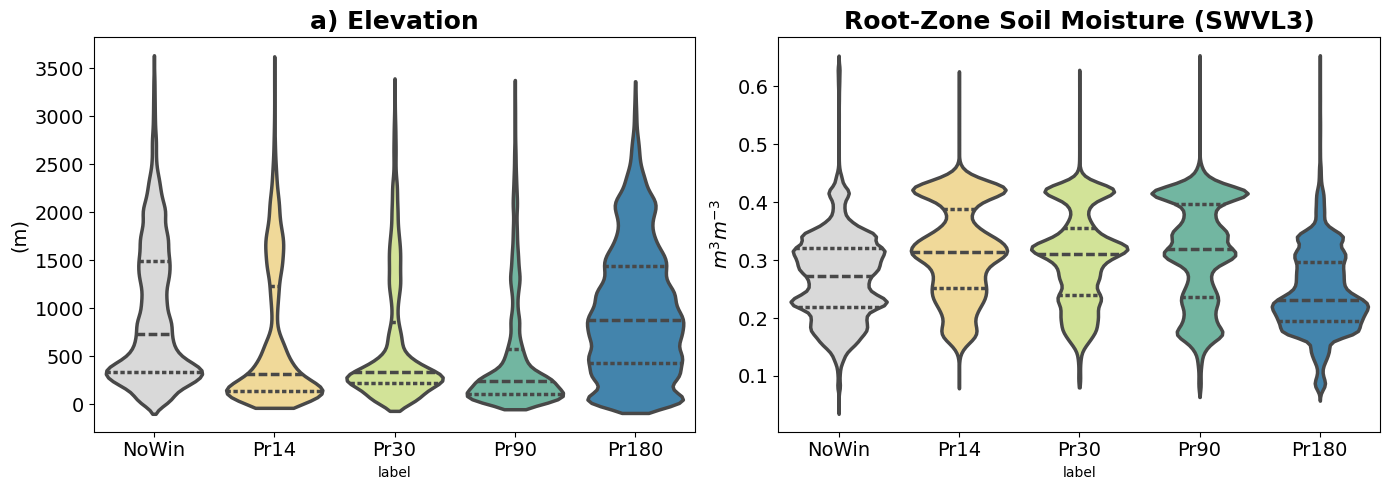

In [ ]:
fig, axes = plt.subplots(1, 2,figsize=(14, 5))

sns.violinplot(data=df_env,x="label",y="elevation",order=order,palette=palette,inner="quart",linewidth=2.5,cut=0,ax=axes[0])
axes[0].set_title("a) Elevation",fontsize=18,weight='bold')
axes[0].set_ylabel("(m)",fontsize=14)
axes[0].tick_params(axis="both",labelsize=14)


sns.violinplot(data=df_env,x="label",y="swvl3",order=order,palette=palette,inner="quart",linewidth=2.5,cut=0,ax=axes[1])
axes[1].set_title("b) Root-Zone Soil Moisture (SWVL3)",fontsize=18,weight='bold')
axes[1].set_ylabel("$m^3 m^{-3}$",fontsize=14)
axes[1].tick_params(axis="both",labelsize=14)

plt.tight_layout()
plt.show()

*Figure 13. Elevation and root-zone soil moisture associated with dominant antecedent precipitation timescales. Violin plots show the distributions of (a) elevation and (b) mean ERA5-Land root-zone soil moisture (SWVL3; 28–100 cm depth) for grid cells classified according to their dominant antecedent precipitation timescale. Dashed lines indicate the 25th, 50th (median), and 75th percentiles of each distribution. Regions favoring $Pr_{90}$ generally occur at lower elevations and under relatively moist soil conditions, whereas regions favoring $Pr_{180}$ are associated with higher elevations and lower root-zone soil moisture. The NoWin class spans a broad range of environments but is generally characterized by intermediate soil moisture and higher elevations than the $Pr_{14}$, $Pr_{30}$, and $Pr_{90}$ classes. These results indicate that dominant antecedent precipitation timescales are associated with distinct hydroclimatic settings defined by both topography and subsurface moisture availability.*

## Figure 11. Dominant Covariate vs Return-Level Sensitivity

In [63]:
def compute_rl_sensitivity(ds, rp=20):
    """
    Return-level sensitivity to GLOST.
    Units:
        °F per °C GLOST
    """
    rl = ds.rl.sel(return_periods=rp)
    d_rl = rl.isel(time=-1)- rl.isel(time=0)
    d_glost = float(ds.covariate1.isel(time=-1).mean({'lon','lat'})- ds.covariate1.isel(time=0).mean({'lon','lat'}))

    return d_rl / d_glost


In [64]:
sens_NoPr = compute_rl_sensitivity(datasets["PrNO"],rp=20)
sens_Pr14 = compute_rl_sensitivity(datasets["Pr14"],rp=20)
sens_Pr30 = compute_rl_sensitivity(datasets["Pr30"],rp=20)
sens_Pr90 = compute_rl_sensitivity(datasets["Pr90"],rp=20)
sens_Pr180 = compute_rl_sensitivity(datasets["Pr180"],rp=20)

In [66]:
dS_Pr14 = sens_Pr14 - sens_NoPr
dS_Pr30 = sens_Pr30 - sens_NoPr
dS_Pr90 = sens_Pr90 - sens_NoPr
dS_Pr180 = sens_Pr180 - sens_NoPr

In [67]:
dS_dom = xr.full_like(dominant_CRPS,np.nan,dtype=float,)
dS_dom = xr.where(dominant_CRPS == 2,dS_Pr14,dS_dom,)
dS_dom = xr.where(dominant_CRPS == 3,dS_Pr30,dS_dom)
dS_dom = xr.where(dominant_CRPS == 4,dS_Pr90,dS_dom)
dS_dom = xr.where(dominant_CRPS == 5,dS_Pr180,dS_dom)
dS_dom = dS_dom.where(landmask)
dS_dom.attrs["long_name"] = ("Return-level sensitivity difference ""relative to NoPr")
dS_dom.attrs["units"] = "degF per degC GLOST"


In [ ]:
records = []

for iclass, (label, period) in classes.items():
    vals = dS_dom.where(dominant_CRPS.where(landmask) == iclass).values.ravel()
    vals = vals[np.isfinite(vals)]
    records.append(pd.DataFrame({"class": iclass, "label": label,"dS": vals}))

df = pd.concat(records,ignore_index=True)

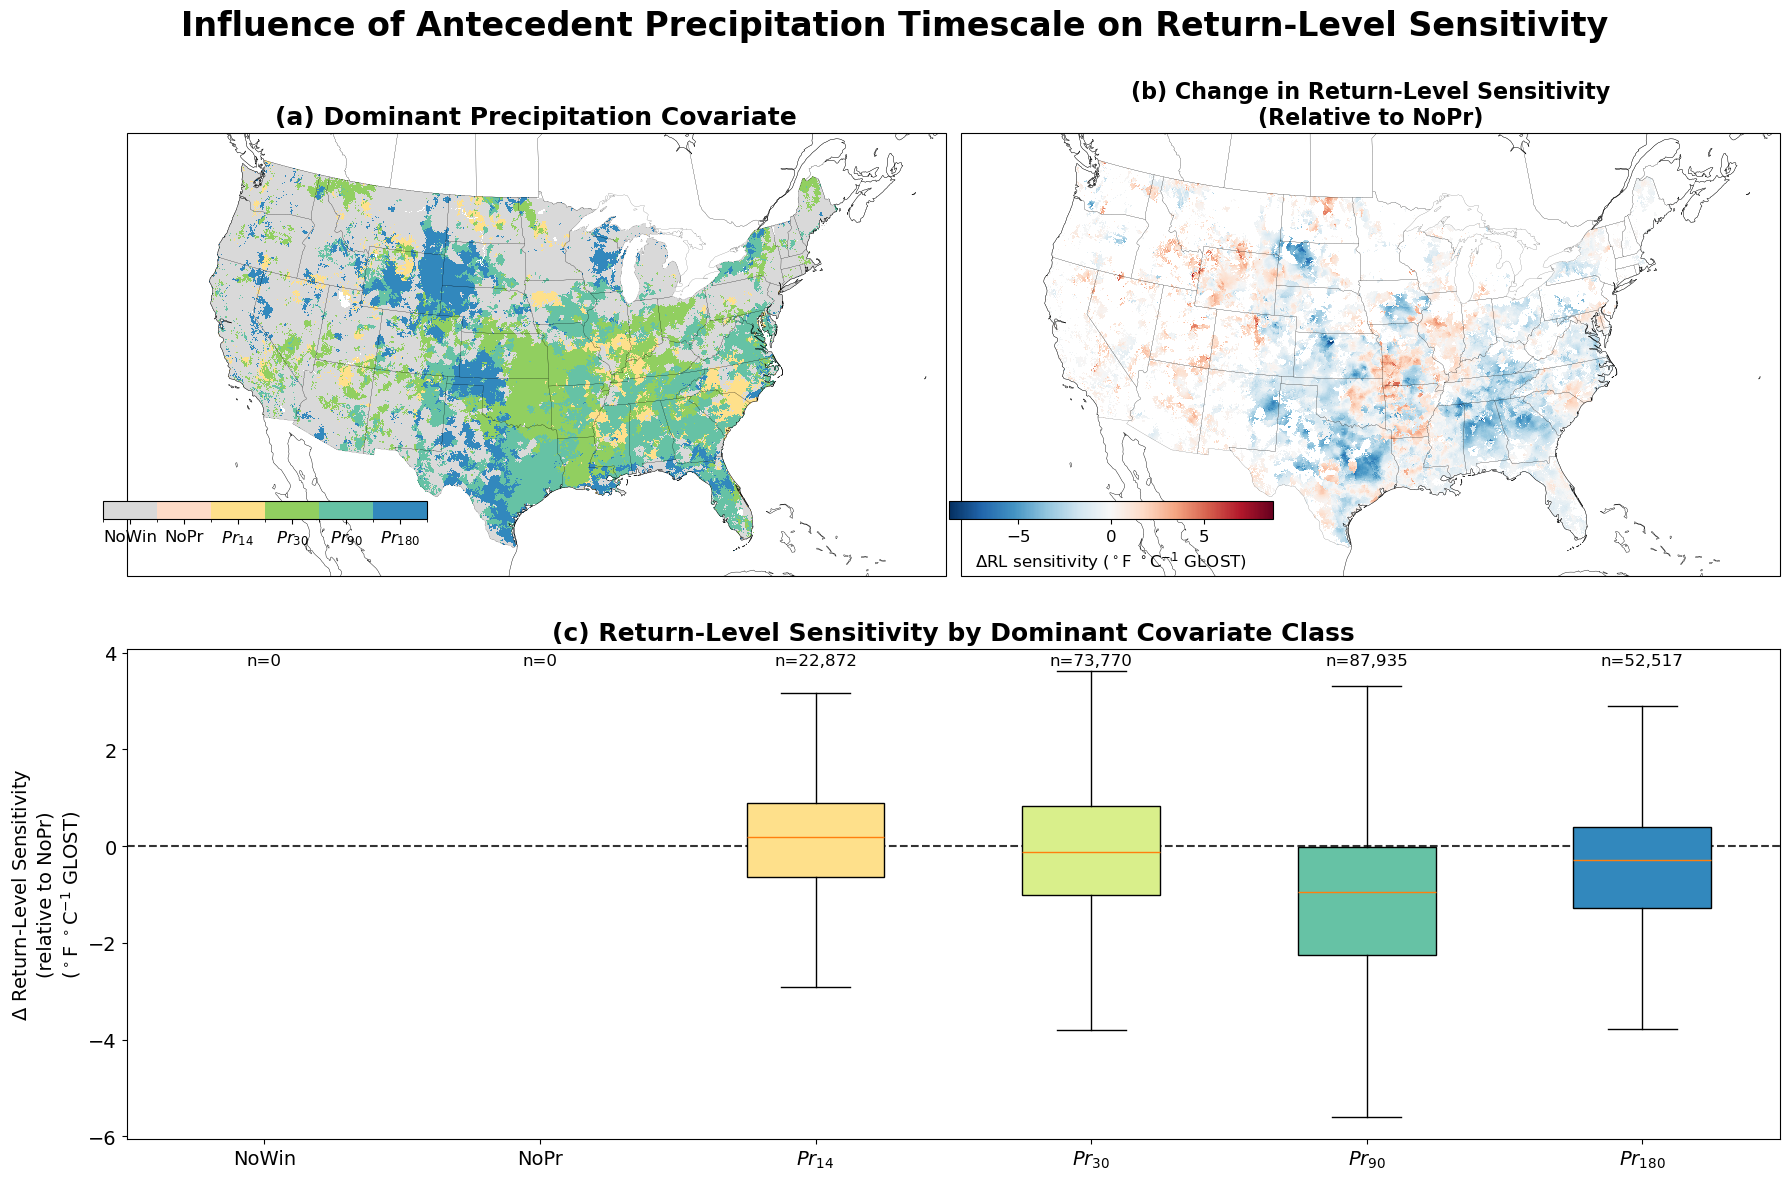

In [72]:
# --------------------------------------------------
# Figure layout
# --------------------------------------------------
fig = plt.figure(figsize=(18, 12))
plt.subplots_adjust(left=0.05,right=0.95,bottom=0.1,top=0.95,hspace=0.1,wspace=0.04)
gs = GridSpec(2,2,figure=fig,height_ratios=[1, 0.8])
# ==================================================
# (a) Dominant covariate
# ==================================================
ax1 = fig.add_subplot(gs[0, 0],projection=proj)

im_a = plot_categorical_map(dominant_CRPS.where(landmask),title="(a) Dominant Precipitation Covariate",cmap=dominant_cmap,norm=dominant_norm,cbar_labels=dominant_labels,ax=ax1,\
    state_borders=state_borders,rivers=None,show_colorbar=False,show_percentages=False,)
# --------------------------------------------------
# Colorbar for panel (a)
# --------------------------------------------------
cax_dom = fig.add_axes( [0.06, 0.555, 0.18, 0.015])
ticks = (np.diff(dominant_norm.boundaries) / 2+ dominant_norm.boundaries[:-1])
cb_dom = fig.colorbar(plt.cm.ScalarMappable(cmap=dominant_cmap,norm=dominant_norm),cax=cax_dom,orientation="horizontal",ticks=ticks)
cb_dom.ax.set_xticklabels([ "NoWin","NoPr", r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$"])
cb_dom.ax.tick_params(labelsize=12)
cb_dom.set_label("",fontsize=12)
# ==================================================
# (b) Annual precipitation map
# ==================================================
ax2 = fig.add_subplot(gs[0, 1],projection=proj)
im_p = dS_dom.where(landmask).plot(ax=ax2,transform=ccrs.PlateCarree(),cmap="RdBu_r",add_colorbar=False)
ax2.coastlines(linewidth=0.3)

if state_borders is not None:
    ax2.add_feature( state_borders,edgecolor="k",linewidth=0.1,zorder=100)
ax2.set_extent((-125, -66.5, 24, 50),crs=ccrs.PlateCarree())

ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.set_title("(b) Change in Return-Level Sensitivity\n(Relative to NoPr)",fontsize=16,fontweight="bold",)
# --------------------------------------------------
# precipitation colorbar
# --------------------------------------------------
cax_p = fig.add_axes([0.53, 0.555, 0.18, 0.015])
cb_p = fig.colorbar(im_p,cax=cax_p,orientation="horizontal")
cb_p.ax.tick_params(labelsize=12)
cb_p.set_label(r"$\Delta$RL sensitivity "
    r"($^\circ$F $^\circ$C$^{-1}$ GLOST)",fontsize=12)

# ==================================================
# (c) Boxplot
# ==================================================
ax3 = fig.add_subplot(gs[1, :])

data = [df.loc[df["label"] == label,"dS"]for label in order]
bp = ax3.boxplot(data,tick_labels=["NoWin","NoPr",r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$",],showfliers=False,patch_artist=True,)

for box, color in zip(bp["boxes"],colors):
    box.set_facecolor(color)
ax3.axhline(y=0,color="black",linestyle="--",linewidth=1.5,alpha=0.8,zorder=0)    
ax3.set_ylabel(r"$\Delta$ Return-Level Sensitivity"
    "\n(relative to NoPr)"
    "\n($^\circ$F $^\circ$C$^{-1}$ GLOST)",fontsize=14)
ax3.set_title("(c) Return-Level Sensitivity by Dominant Covariate Class",fontsize=18,fontweight="bold")
ax3.tick_params(axis="both",labelsize=14)
# sample size labels
for i, label in enumerate(order, start=1):
    n = (df["label"] == label).sum()
    ax3.text( i,ax3.get_ylim()[1] * 0.98,f"n={n:,}",ha="center",va="top",fontsize=12)

fig.suptitle("Influence of Antecedent Precipitation Timescale on Return-Level Sensitivity",fontsize=24,fontweight="bold",)
plt.tight_layout()
plt.show()

*Figure 12. Relationship between dominant antecedent precipitation timescales and return-level sensitivity to warming. (a) Dominant antecedent precipitation timescale identified from cross-validated CRPS using pairwise Algorithm B1 comparisons. The selected class corresponds to the precipitation accumulation period that yields the best predictive performance at each grid cell. (b) Difference in 20-year return-level sensitivity to GLOST relative to the corresponding model without a precipitation covariate (NoPr). Positive values indicate higher estimated return-level sensitivity in the precipitation-based model, whereas negative values indicate lower estimated sensitivity relative to NoPr. (c) Distribution of return-level sensitivity differences associated with each dominant antecedent precipitation timescale; sample sizes are indicated above each boxplot. Median sensitivity differences vary among the dominant timescale classes, with$Pr_{90}$ and $Pr_{180}$ tending to exhibit more negative values than $Pr_{14}$ and $Pr_{30}$. These results indicate that the estimated sensitivity of extreme-temperature return levels to GLOST differs among models that favor different antecedent precipitation accumulation periods.*

In [73]:
# --------------------------------------------------
# Return period
# --------------------------------------------------
rp = 20
# --------------------------------------------------
# Change in RL20 for each model
# --------------------------------------------------
delta_rl = {}
for model in models:
    rl = datasets[model]["rl"].sel(return_periods=rp)
    delta_rl[model] = (rl.isel(time=-1)- rl.isel(time=0))
    delta_rl[model].attrs["units"] = "°F"

In [74]:
delta_rl_dom = xr.full_like(dominant_CRPS,np.nan,dtype=float,)
delta_rl_dom = xr.where(dominant_CRPS == 1,delta_rl["PrNO"],delta_rl_dom)
delta_rl_dom = xr.where(dominant_CRPS == 2,delta_rl["Pr14"],delta_rl_dom)
delta_rl_dom = xr.where(dominant_CRPS == 3,delta_rl["Pr30"],delta_rl_dom)
delta_rl_dom = xr.where(dominant_CRPS == 4,delta_rl["Pr90"],delta_rl_dom)
delta_rl_dom = xr.where(dominant_CRPS == 5,delta_rl["Pr180"],delta_rl_dom)
delta_rl_dom = delta_rl_dom.where(landmask)
delta_rl_dom.attrs["long_name"] = f"Change in {rp}-year return level"
delta_rl_dom.attrs["units"] = "degF"

In [76]:
records = []

for iclass, (label, period) in classes.items():
    vals = delta_rl_dom.where(dominant_CRPS.where(landmask) == iclass).values.ravel()
    vals = vals[np.isfinite(vals)]
    records.append(pd.DataFrame({"class": iclass, "label": label,"dRL": vals}))

df = pd.concat(records,ignore_index=True)

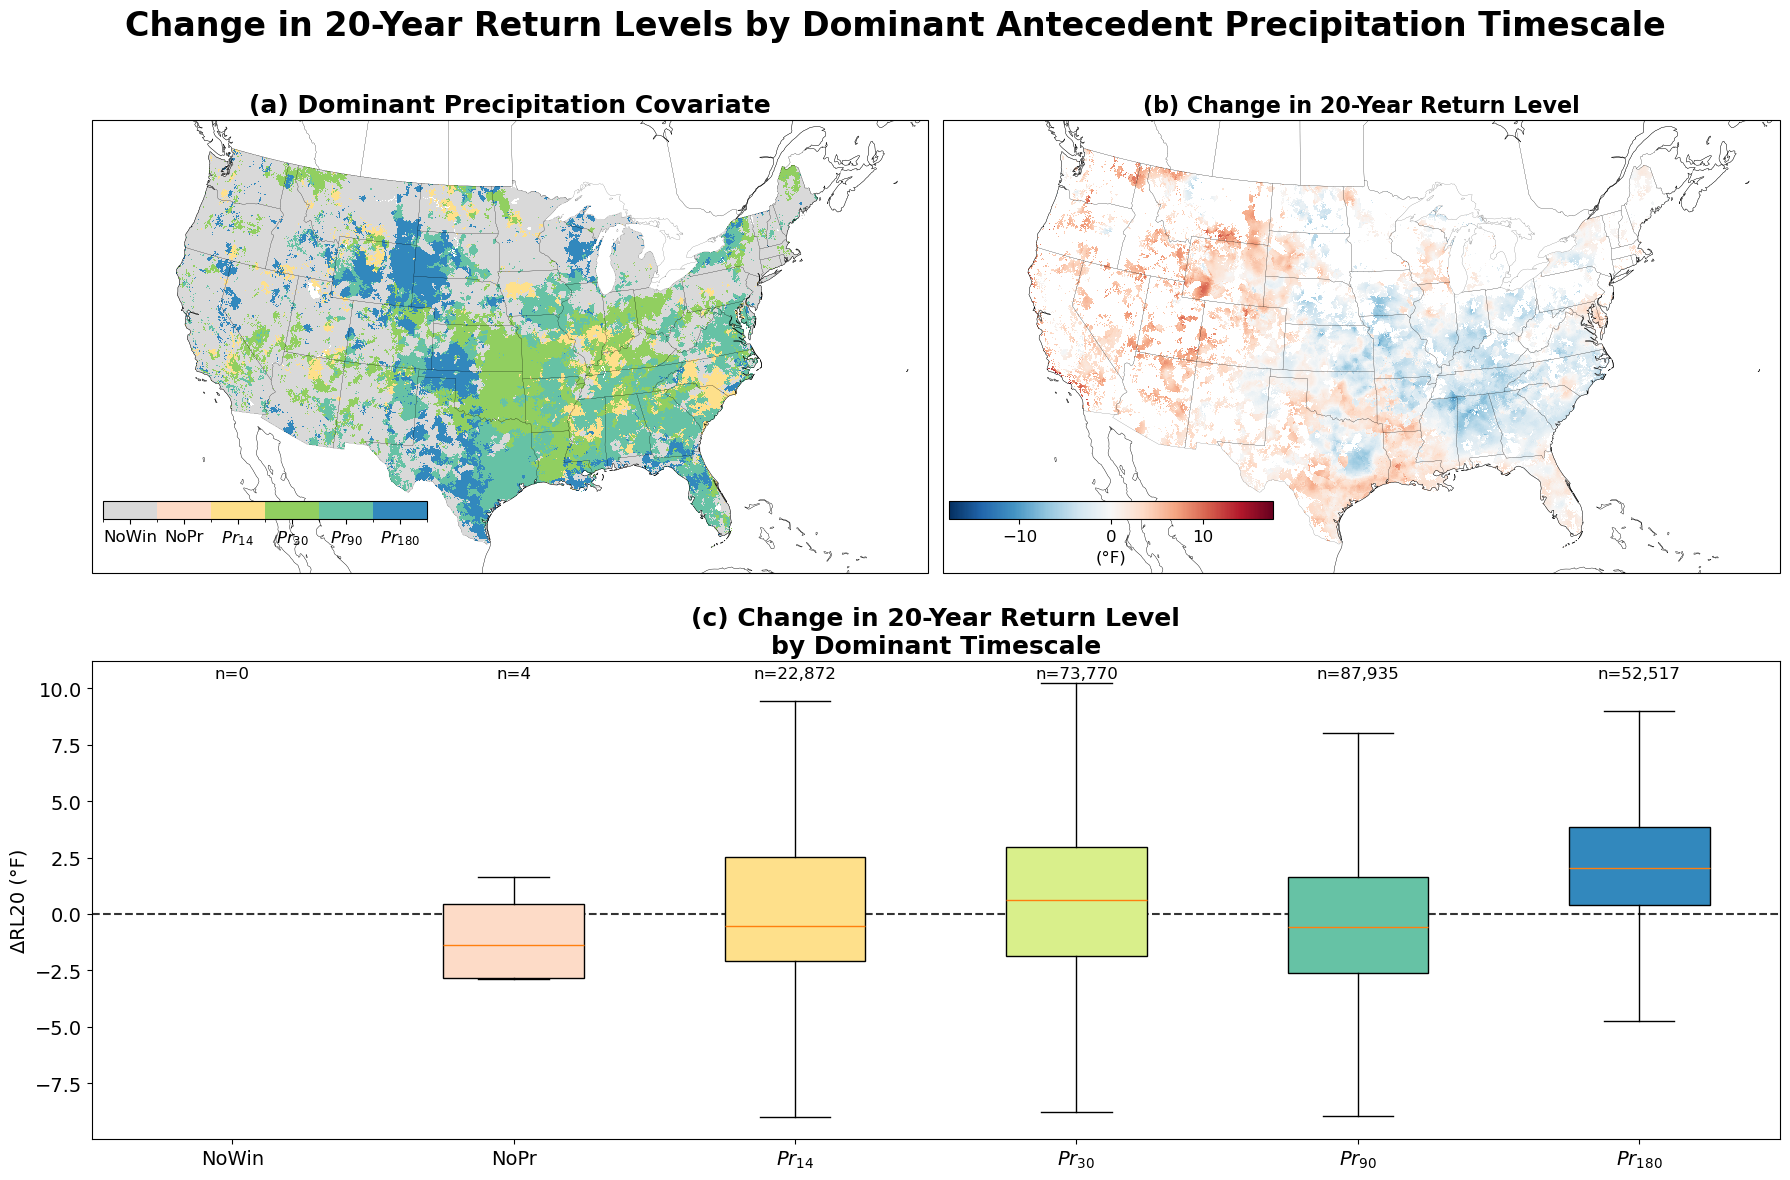

In [79]:
# --------------------------------------------------
# Figure layout
# --------------------------------------------------
fig = plt.figure(figsize=(18, 12))
plt.subplots_adjust(left=0.05,right=0.95,bottom=0.1,top=0.95,hspace=0.1,wspace=0.04)
gs = GridSpec(2,2,figure=fig,height_ratios=[1, 0.8])
# ==================================================
# (a) Dominant covariate
# ==================================================
ax1 = fig.add_subplot(gs[0, 0],projection=proj)

im_a = plot_categorical_map(dominant_CRPS.where(landmask),title="(a) Dominant Precipitation Covariate",cmap=dominant_cmap,norm=dominant_norm,cbar_labels=dominant_labels,ax=ax1,\
    state_borders=state_borders,rivers=None,show_colorbar=False,show_percentages=False,)
# --------------------------------------------------
# Colorbar for panel (a)
# --------------------------------------------------
cax_dom = fig.add_axes( [0.06, 0.555, 0.18, 0.015])
ticks = (np.diff(dominant_norm.boundaries) / 2+ dominant_norm.boundaries[:-1])
cb_dom = fig.colorbar(plt.cm.ScalarMappable(cmap=dominant_cmap,norm=dominant_norm),cax=cax_dom,orientation="horizontal",ticks=ticks)
cb_dom.ax.set_xticklabels([ "NoWin","NoPr", r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$"])
cb_dom.ax.tick_params(labelsize=12)
cb_dom.set_label("",fontsize=12)
# ==================================================
# (b) Annual precipitation map
# ==================================================
ax2 = fig.add_subplot(gs[0, 1],projection=proj)
im_p = delta_rl_dom.where(landmask).plot(ax=ax2,transform=ccrs.PlateCarree(),cmap="RdBu_r",add_colorbar=False)
ax2.coastlines(linewidth=0.3)

if state_borders is not None:
    ax2.add_feature( state_borders,edgecolor="k",linewidth=0.1,zorder=100)
ax2.set_extent((-125, -66.5, 24, 50),crs=ccrs.PlateCarree())

ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.set_title(f"(b) Change in {rp}-Year Return Level",fontsize=16,fontweight="bold",)
# --------------------------------------------------
# precipitation colorbar
# --------------------------------------------------
cax_p = fig.add_axes([0.53, 0.555, 0.18, 0.015])
cb_p = fig.colorbar(im_p,cax=cax_p,orientation="horizontal")
cb_p.ax.tick_params(labelsize=12)
cb_p.set_label(f"(°F)",fontsize=12)

# ==================================================
# (c) Boxplot
# ==================================================
ax3 = fig.add_subplot(gs[1, :])

data = [df.loc[df["label"] == label,"dRL"]for label in order]
bp = ax3.boxplot(data,tick_labels=["NoWin","NoPr",r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$",],showfliers=False,patch_artist=True,)

for box, color in zip(bp["boxes"],colors):
    box.set_facecolor(color)
ax3.axhline(y=0,color="black",linestyle="--",linewidth=1.5,alpha=0.8,zorder=0)    
ax3.set_ylabel(f"ΔRL{rp} (°F)",fontsize=14)
ax3.set_title(f"(c) Change in {rp}-Year Return Level\nby Dominant Timescale",fontsize=18,fontweight="bold")
ax3.tick_params(axis="both",labelsize=14)
# sample size labels
for i, label in enumerate(order, start=1):
    n = (df["label"] == label).sum()
    ax3.text( i,ax3.get_ylim()[1] * 0.98,f"n={n:,}",ha="center",va="top",fontsize=12)

fig.suptitle(f"Change in {rp}-Year Return Levels by Dominant Antecedent Precipitation Timescale",fontsize=24,fontweight="bold",)
plt.tight_layout()
plt.show()

*Figure 13. Change in 20-year return levels by dominant antecedent precipitation timescale. (a) Dominant antecedent precipitation timescale identified from cross-validated CRPS using pairwise Algorithm B1 comparisons. The selected class corresponds to the precipitation accumulation period that provides the best predictive performance at each grid cell. (b) Change in the 20-year return level ($\Delta RL_{20}$) between the beginning and end of the analysis period for the model associated with the dominant antecedent precipitation timescale. Positive values indicate an increase in the magnitude of 20-year temperature extremes over time, while negative values indicate a decrease. (c) Distribution of $\Delta RL_{20}$ associated with each dominant antecedent precipitation timescale; sample sizes are indicated above each boxplot. Differences among the dominant timescale classes are evident, with regions favoring $Pr_{180}$ generally exhibiting larger positive changes in return levels than regions favoring $Pr_{90}$. However, substantial overlap exists among the distributions, indicating that changes in extreme-temperature return levels are not uniquely associated with any single antecedent precipitation timescale.*

## Future Figures to Test the Physical Controls of Dominant Precipitation Covariates
The current analysis identifies spatially coherent dominant precipitation accumulation periods but does not directly determine the physical mechanisms responsible for these patterns. The following analyses would provide quantitative tests of the proposed hypotheses.

# Figure 7. Dominant Precipitation Covariate and Aridity Index
Hypothesis: Dominant accumulation period increases with climatic moisture availability.

Panels

(a) Dominant precipitation covariate
(b) Aridity Index ($P/PET$)
(c) Mean aridity index by dominant covariate class
Expected result

Humid environments preferentially select $Pr_{90}$–$Pr_{180}$.
Arid environments preferentially select $Pr_{30}$, $Pr_{14}$, or exhibit no dominant covariate.
Draft caption

Figure 7. Relationship between dominant precipitation covariates and climatic aridity. Longer accumulation periods are expected in humid regions where precipitation anomalies persist through soil-moisture storage and evapotranspiration feedbacks, whereas shorter accumulation periods are expected in moisture-limited environments.


# Figure 9. Dominant Precipitation Covariate and Evapotranspiration
Hypothesis: Regions exhibiting strong evapotranspiration feedbacks require longer precipitation accumulation periods.

Panels

(a) Dominant precipitation covariate
(b) Warm-season actual evapotranspiration
(c) Mean evapotranspiration by dominant covariate
Expected result

Longer accumulation periods coincide with regions characterized by high evapotranspiration.
Draft caption

Figure 9. Relationship between dominant precipitation covariates and evapotranspiration. Regions favoring long accumulation periods generally exhibit large evapotranspiration fluxes, suggesting that precipitation influences temperature extremes through land-surface moisture storage and energy-partitioning processes.



# Figure 11. Dominant Precipitation Covariate and Land Cover
Hypothesis: Land-atmosphere coupling varies by vegetation type and contributes to the preferred accumulation period.

Panels

(a) Dominant precipitation covariate
(b) NLCD land-cover classification
(c) Fraction of each dominant covariate within major land-cover classes
Expected result

Intermediate accumulation periods ($Pr_{30}$–$Pr_{45}$) are more common in agricultural regions.
Longer accumulation periods are more common in forested humid regions.
Draft caption

Figure 11. Relationship between dominant precipitation covariates and land cover. The analysis evaluates whether vegetation type and land management influence the precipitation-memory timescale associated with temperature extremes.

# Figure 12. Summary Mechanism Figure
Hypothesis: Regional hydroclimatic memory controls the preferred precipitation accumulation period.

Panels

Dominant precipitation covariate
Mean annual precipitation
Soil moisture
Aridity index
Elevation
Expected result

Consistent transition from short accumulation periods in drier transitional climates to longer accumulation periods in humid regions characterized by greater soil-moisture storage and evapotranspiration.
Draft caption

Figure 12. Synthesis of hydroclimatic controls on dominant precipitation accumulation periods. Spatial comparisons suggest that the preferred precipitation accumulation period increases with hydroclimatic memory and moisture availability, while regions of complex topography exhibit weak or absent precipitation controls on extreme temperatures.


## References

Daly, C., Halbleib, M., Smith, J. I., Gibson, W. P., Doggett, M. K., Taylor, G. H., Curtis, J., & Pasteris, P. P. (2008). Physiographically sensitive mapping of climatological temperature and precipitation across the conterminous United States. *International Journal of Climatology, 28*(15), 2031–2064. https://doi.org/10.1002/joc.1688

Entin, J. K., Robock, A., Vinnikov, K. Y., Hollinger, S. E., Liu, S., & Namkhai, A. (2000). Temporal and spatial scales of observed soil moisture variations in the extratropics. *Journal of Geophysical Research: Atmospheres, 105*(D9), 11865–11877. https://doi.org/10.1029/2000JD900051

Ford, T. W., & Labosier, C. F. (2017). Meteorological conditions associated with the onset of flash drought in the eastern United States. *Agricultural and Forest Meteorology, 247*, 414–423. https://doi.org/10.1016/j.agrformet.2017.08.031

Koster, R. D., Dirmeyer, P. A., Guo, Z., Bonan, G., Chan, E., Cox, P., Gordon, C. T., Kanae, S., Kowalczyk, E., Lawrence, D., Liu, P., Lu, C.-H., Malyshev, S., McAvaney, B., Mitchell, K., Mocko, D., Oki, T., Oleson, K., Pitman, A., ... Yamada, T. (2004). Regions of strong coupling between soil moisture and precipitation. *Science, 305*(5687), 1138–1140. https://doi.org/10.1126/science.1100217

Miralles, D. G., Gentine, P., Seneviratne, S. I., & Teuling, A. J. (2019). Land–atmospheric feedbacks during droughts and heatwaves: State of the science and current challenges. *Annals of the New York Academy of

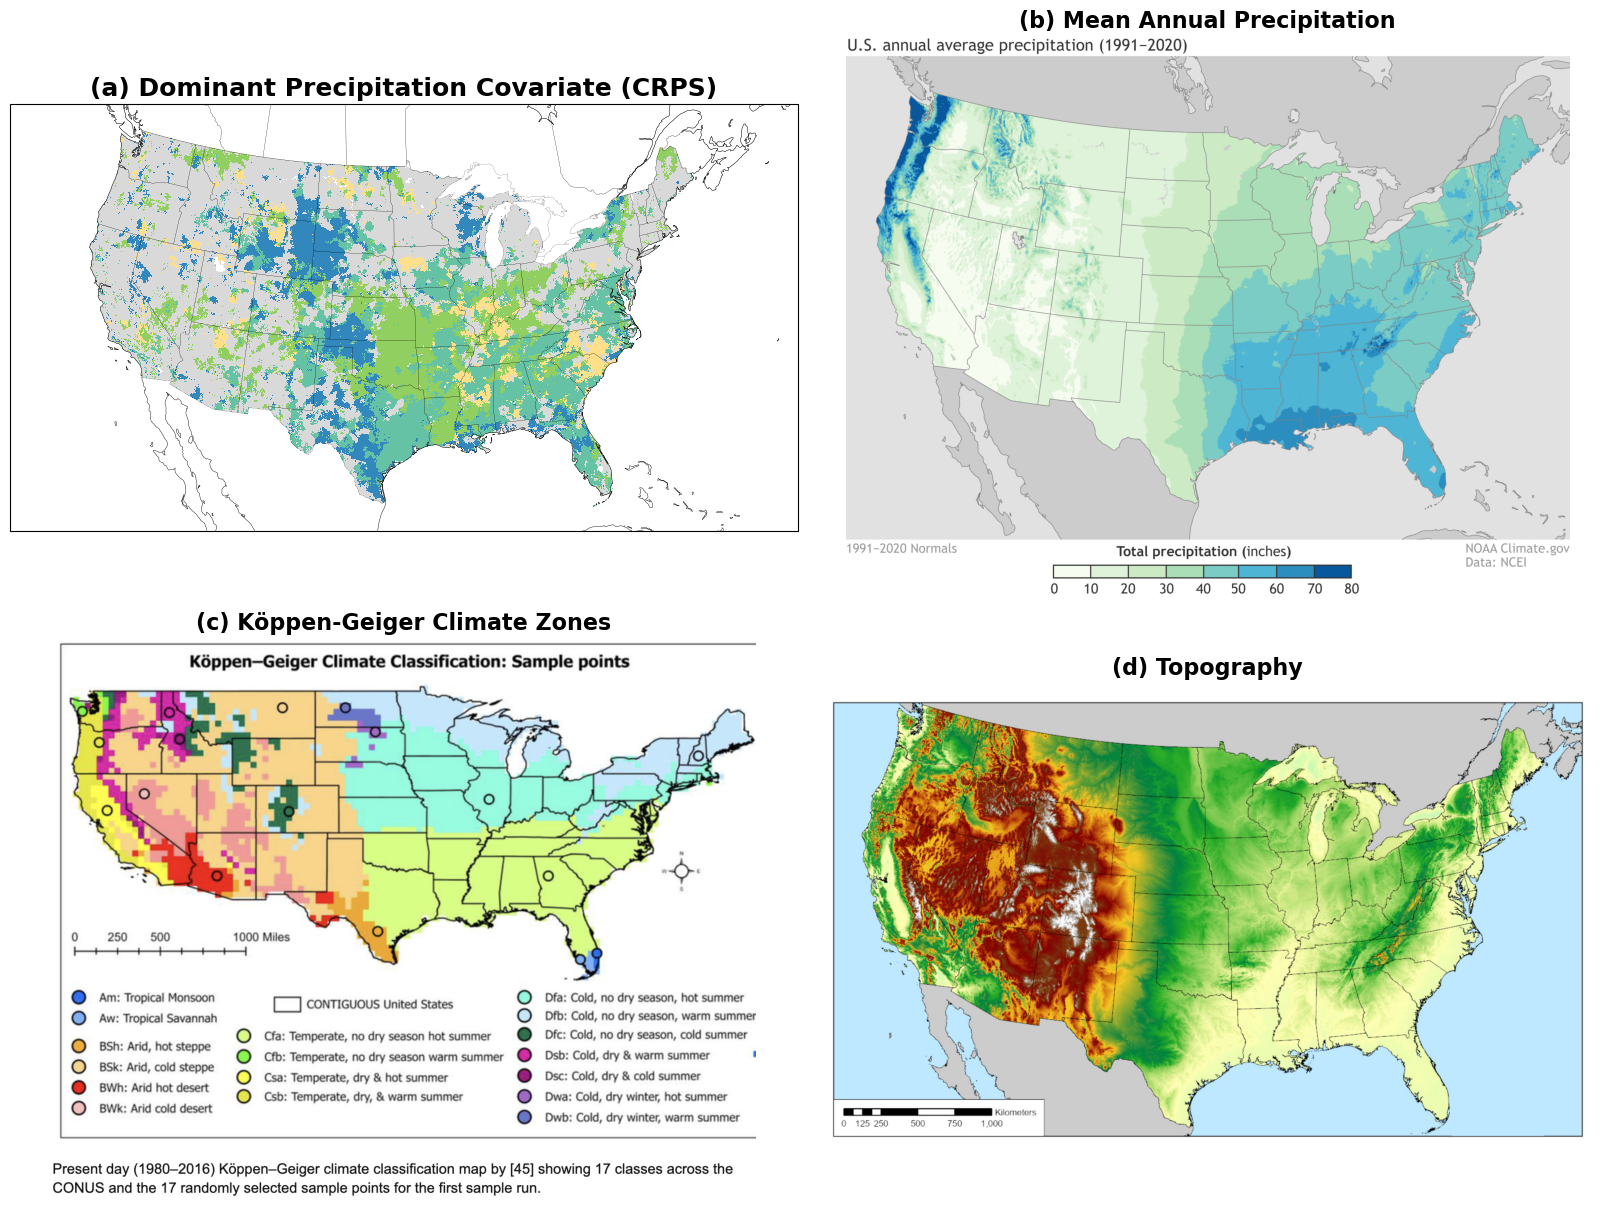

In [ ]:

# --------------------------------------------------
# Read images
# --------------------------------------------------

img_precip = np.array( Image.open("/Users/gahe5417/SCRIPTS/TXx/NOAA_AnnualPrecipitation_1991_2020.png"))
img_koppen = np.array( Image.open("/Users/gahe5417/SCRIPTS/TXx/koppen_geiger.png"))
img_topo = np.array( Image.open("/Users/gahe5417/SCRIPTS/TXx/CONUS-MT_2026_color_topography.jpg"))

# --------------------------------------------------
# Figure
# --------------------------------------------------

fig, axes = plt.subplots(2,2, figsize=(16, 12), constrained_layout=True,)
gs = fig.add_gridspec(2, 2)

ax1 = fig.add_subplot(gs[0,0], projection=proj)  # Cartopy
ax2 = fig.add_subplot(gs[0,1])                   # image
ax3 = fig.add_subplot(gs[1,0])                   # image
ax4 = fig.add_subplot(gs[1,1]) 
# --------------------------------------------------
# (a) Dominant covariate
# --------------------------------------------------
plt.sca(axes[0, 0])
plot_categorical_map(
    dominant_CRPS.where(landmask),
    title="(a) Dominant Precipitation Covariate (CRPS)",
    cmap=dominant_cmap,
    norm=dominant_norm,
    cbar_labels=dominant_labels,
    ax=ax1,             # creates its own map
    proj=proj,
    state_borders=state_borders,
    rivers=None,
    show_colorbar=False,
    show_percentages=False,
)
# Remove placeholder axis
axes[0,0].remove()
# --------------------------------------------------
# (b) Annual precipitation
# --------------------------------------------------
ax2.imshow(img_precip)
ax2.set_title( "(b) Mean Annual Precipitation",fontsize=16,fontweight="bold")
ax2.axis("off")
axes[0,1].remove()
# --------------------------------------------------
# (c) Köppen-Geiger
# --------------------------------------------------
ax3.imshow(img_koppen)
ax3.set_title("(c) Köppen-Geiger Climate Zones", fontsize=16,fontweight="bold")
ax3.axis("off")
axes[1,0].remove()
# --------------------------------------------------
# (d) Topography
# --------------------------------------------------
ax4.imshow(img_topo)
ax4.set_title("(d) Topography",fontsize=16, fontweight="bold")
ax4.axis("off")
axes[1,1].remove()

plt.show()

https://www.researchgate.net/figure/Present-day-1980-2016-Koeppen-Geiger-climate-classification-map-by-45-showing-17_fig2_376483233 <br>
topographie USGS